In [1]:
!pip install --extra-index-url https://download.pytorch.org/whl/cpu "numpy==2.5.4" "pandas==3.0.6" "scipy==1.18.1" "scikit-learn==1.9.1" "lightgbm==4.7.0" "catboost==1.2.10" "torch==2.5.1+cpu" "matplotlib==3.11.2" "seaborn==0.13.2" "ipython==9.17.1" "matplotlib-inline==0.2.2"

Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cpu


# Aktuaria dan Machine Learning untuk Prediksi Tiket D4–D10
### Studi Perkembangan Penjualan, Koreksi Neural, dan Learned Credibility

**Tembok Ratapan Solo**

JOINTS 2026 — Laporan Teknis Reproduktif

Seluruh bobot pada eksekusi ini dilatih ulang dari label resmi dan konteks eksternal historis yang diizinkan. Kalender serta parameter routing beku disertakan dalam notebook. Identitas tim tidak berubah menurut model yang terpilih.

## Daftar Isi

1. Abstrak
2. Pendahuluan dan Pertanyaan Penelitian
3. Penelitian Terkait
4. Reproduksibilitas
5. Data dan Exploratory Data Analysis
6. Preprocessing dan Feature Engineering
7. Pendekatan 1 — Actuarial Features + LightGBM
8. Pendekatan 2 — Negative Binomial Prior + Neural Correction
9. Pendekatan 3 — Learned Credibility Mixture
10. Validasi Kronologis dan Ablation
11. Interpretabilitas
12. Biaya Komputasi
13. Pelatihan Final, Penyimpanan, dan Inferensi
    - 13.1 Compact mixture dan refit penuh
14. Pembahasan
15. Keterbatasan
16. Kesimpulan
17. Referensi

## 1. Abstrak

Permintaan tiket film harus diprediksi pada D4–D10 ketika hanya D1–D3 yang tersedia. Laporan ini menguji tiga cara memasukkan struktur aktuaria ke pembelajaran mesin: fitur perkembangan dan credibility pada boosted trees, prior Negative Binomial dengan koreksi neural multiplikatif, serta campuran ahli dengan bobot credibility yang dipelajari. EDA memeriksa mekanisme pencatatan transaksi, pembukaan lintas bioskop, penghentian tayang, distribusi skala, kalender, dan pergeseran populasi. Lima jendela kronologis dengan pemisahan film mengevaluasi MASE resmi. Semua tabel hasil, interval ketidakpastian, keputusan pemilihan, dan ukuran model dihitung oleh sel executable di bawah; ringkasan numerik diberikan setelah eksekusi.

Bagian akhir menambahkan compact mixture dengan bobot ahli hasil pelatihan resmi dan parameter routing yang dibekukan dari optimasi adaptif terpisah. Estimasi generalisasi dari backtest dan kriteria reproduksi konfigurasi tersebut adalah dua hasil yang berbeda; laporan tidak menyamakan keduanya.

## 2. Pendahuluan dan Pertanyaan Penelitian

Tiga observasi awal bukan sampel identik dari satu tingkat permintaan yang tetap. Pembukaan dapat bertahap antar lokasi; penurunan show dapat menandakan penghentian tayang; akhir pekan dapat meningkatkan penjualan ketika tren dasar sedang turun. Data historis juga merupakan tabel transaksi: ketiadaan baris harus ditafsirkan melalui kontrak target, bukan sekadar dihapus sebagai missing value.

- **RQ1:** Apakah fitur perkembangan dan credibility meningkatkan MASE dibanding fitur pembukaan biasa?
- **RQ2:** Apakah koreksi neural memperbaiki prior aktuaria di luar periode latih?
- **RQ3:** Apakah gate yang bergantung pada kualitas riwayat mengungguli campuran statis?
- **RQ4:** Bagaimana hasil berubah menurut film, horizon, skala, nol/non-nol, seed, dan penggunaan prior eksternal?
- **RQ5:** Apakah semua state inferensi tetap di bawah batas 200 MB dan dapat dimuat ulang?

## 3. Penelitian Terkait dan Posisi Metode

Development factors memproyeksikan pertumbuhan kumulatif; credibility melakukan shrinkage dari pengalaman individual menuju pengalaman kelompok. Di sini keduanya diadaptasi untuk penjualan tiket, sehingga asumsi homogenitas dan perkembangan klaim asuransi tidak otomatis berlaku. Prior Negative Binomial menangani overdispersion, sedangkan koreksi neural mengadaptasi hubungan offset model klasik dengan residual nonlinear dalam CANN [1]. Gate input-dependent menggeneralisasi shrinkage melalui beberapa ahli [2].

Gaya analisis dari notebook referensi Three Makasih diadaptasi sebagai pemeriksaan hipotesis, pengujian kebocoran, dan beberapa pendekatan yang dibandingkan. Format laporan mengikuti notebook Tembok Ratapan Solo SSF. Hasil dan implementasi untuk tiket dihitung kembali di sini.

## 4. Dependensi dan Reproduksibilitas

Sel pertama memasang versi pustaka yang sama dengan eksekusi model terverifikasi. Gunakan Python 3.12 dan kernel baru. Notebook pengumpulan ini menjalankan **inference-only**: bobot, encoder, prior, dan router dimuat dari `Tembok Ratapan Solo.npz`; tidak ada pelatihan ulang pada Run All.

Ekstrak ZIP pengumpulan ke satu folder dan jalankan notebook dari folder tersebut. Letakkan ZIP kompetisi `datajointsxinspire.zip` di folder yang sama, atau isi `JOINTS_OFFICIAL_ZIP` dengan lokasinya. ZIP kompetisi disediakan evaluator dan tidak diduplikasi dalam ZIP pengumpulan.

Kedua data eksternal dibaca langsung dengan relative path: `cinepoint_pre_cutoff.csv` untuk konteks historis nasional dan `kalender_libur_pre_cutoff.csv` untuk kalender yang telah dipublikasikan sebelum 30 September 2025. Tidak ada unduhan dataset selama inferensi.

Grafik EDA dibangun ulang dari input. Hasil validasi dan ablation berasal dari pelatihan bersih yang telah terdokumentasi dan diberi label demikian; Run All tidak mengulang eksperimen pelatihan tersebut. Keluaran baru ditulis ke `joints_submission_output/`, termasuk `submission.csv`, prediksi ketiga baseline, dan receipt verifikasi.

Konfigurasi yang boleh diubah adalah lokasi ZIP kompetisi dan jumlah thread CPU. Berkas bobot serta dua CSV eksternal dicari di `datasets/` lalu di root repositori. ZIP kompetisi dicari dari root repositori, termasuk subfolder `datasets/`, atau melalui `JOINTS_OFFICIAL_ZIP`. NPZ merupakan container array byte non-pickle: indeks nama, ukuran, dan SHA256 diperiksa sebelum file state dimuat. Seluruh state inferensi dari keempat varian tersedia dalam satu berkas bobot.

Router compact merupakan parameter model yang dibekukan melalui optimasi adaptif; pemilihannya tidak dijalankan ulang dalam notebook. Validasi kronologis mengacu pada baseline yang dievaluasi dalam protokol tersebut.

In [2]:
from pathlib import Path
import os, sys, re, json, time, hashlib, zipfile, gc, platform, socket, pickle
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.optimize import minimize
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import torch
from torch import nn

# Resolve inputs from the repository root, even when the notebook kernel starts in notebook/.
def find_project_root():
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "notebook" / "Tembok Ratapan Solo.ipynb").is_file():
            return candidate
    return start

PROJECT_ROOT = find_project_root()
os.chdir(PROJECT_ROOT)
DATASET_DIR = PROJECT_ROOT / "datasets"

def input_path(name):
    candidates = [DATASET_DIR / name, PROJECT_ROOT / name]
    return next((candidate for candidate in candidates if candidate.is_file()), candidates[0])

OFFICIAL_FILES = ['train.csv','test_history.csv','test.csv','movies.csv',
                  'holidays.csv','ticket_prices.csv','sample_submission.csv']
KEY = ['movie_title','cinema_ids','date_show']
FOLDS = [('mei','2025-05-01','2025-06-01'),('juni','2025-06-01','2025-07-01'),
         ('juli','2025-07-01','2025-08-01'),('agustus','2025-08-01','2025-09-01'),
         ('september','2025-09-01','2025-10-01')]
SEEDS = [int(x) for x in os.environ.get('JOINTS_SEEDS','42,137,2026').split(',')]
QUANTILES = np.array([.01,.05,.10,.20,.30,.40,.50,.70,.90])
LIMIT_BYTES = 200_000_000
THREADS = int(os.environ.get('JOINTS_THREADS','4'))
torch.set_num_threads(THREADS)
DEVICE = os.environ.get('JOINTS_DEVICE','cpu')
if DEVICE=='auto':DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
if DEVICE not in ['cpu','cuda']:raise ValueError('JOINTS_DEVICE must be cpu, cuda, or auto')
if DEVICE=='cuda' and not torch.cuda.is_available():raise RuntimeError('CUDA requested but unavailable')

def sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda:f.read(1048576),b''): h.update(b)
    return h.hexdigest()

def write_json(path,value):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(value,indent=2,default=str,allow_nan=False)+'\n')

def log(event,**value):
    print(json.dumps(dict(event=event,**value),default=str),flush=True)

def title_key(value):
    return re.sub(r'[^A-Z0-9]+','',base_title(value))

def base_title(value):
    value=re.sub(r'\s+',' ',str(value).upper()).strip()
    return re.sub(r'\s*(?:\((?:IMAX|3D|2D|4DX|DOLBY|SCREENX)[^)]*\)|\b(?:IMAX|3D|2D|4DX|SCREENX))\s*$','',value).strip()

In [3]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png')
sns.set_theme(style='whitegrid',context='notebook')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':140,'axes.spines.top':False,'axes.spines.right':False})
COLORS=['#315B88','#489C91','#DA8A4E','#8966A6','#B8556B']

def locate_zip(name):
    direct=Path(name)
    if direct.exists():return direct.resolve()
    roots=[Path.cwd(),Path.cwd().parent,Path('/kaggle/input'),Path('/content')]
    for root in roots:
        if root.exists():
            matches=sorted(root.rglob(name))
            if matches:return matches[0].resolve()
    raise FileNotFoundError('Tentukan path ZIP pada variabel konfigurasi: '+name)

OFFICIAL_ZIP=Path(os.environ['JOINTS_OFFICIAL_ZIP']) if os.environ.get('JOINTS_OFFICIAL_ZIP') else locate_zip('datajointsxinspire.zip')
EXTERNAL_ZIP=input_path('cinepoint_pre_cutoff.csv')
OUTPUT=Path('joints_submission_output').resolve()
OUTPUT.mkdir(parents=True,exist_ok=True)
FIGURES=OUTPUT/'figures';FIGURES.mkdir(exist_ok=True)
STARTED=time.perf_counter()
def finish_figure(name):
    plt.tight_layout();plt.savefig(FIGURES/(name+'.png'),bbox_inches='tight')
    display(plt.gcf());plt.close()
print('ZIP resmi:',OFFICIAL_ZIP.name,'| input eksternal:',EXTERNAL_ZIP.name)
print('Perangkat:',DEVICE,'| threads:',THREADS,'| seeds:',SEEDS)

ZIP resmi: datajointsxinspire.zip | input eksternal: cinepoint_pre_cutoff.csv
Perangkat: cpu | threads: 4 | seeds: [42, 137, 2026]


### Memuat state inferensi

State tiap pendekatan diverifikasi terhadap hash yang tersimpan. NPZ memuat bobot jaringan, model pohon, encoder, prior aktuaria, konfigurasi, dan runtime yang diperlukan. Kalender dibentuk dari CSV yang terlampir; kecocokannya dengan kalender state model diperiksa sebelum prediksi.

In [4]:
import tempfile, importlib.util
from pathlib import PurePosixPath

MODEL_FILE = input_path("Tembok Ratapan Solo.npz")
EXTERNAL_CSV = input_path("cinepoint_pre_cutoff.csv")
CALENDAR_CSV = input_path("kalender_libur_pre_cutoff.csv")
for required in [MODEL_FILE, EXTERNAL_CSV, CALENDAR_CSV]:
    if not required.is_file():
        raise FileNotFoundError(f"Berkas pengumpulan tidak ditemukan: {required}")
assert MODEL_FILE.stat().st_size < LIMIT_BYTES

# CSV eksternal dibaca langsung melalui relative path.
external_csv_raw = pd.read_csv(EXTERNAL_CSV)
calendar_csv = pd.read_csv(CALENDAR_CSV, dtype=str)
cutoff = pd.Timestamp("2025-09-30", tz="UTC")
assert pd.to_datetime(external_csv_raw.available_at, utc=True).lt(cutoff).all()
assert pd.to_datetime(external_csv_raw.source_updated_at, utc=True).lt(cutoff).all()
assert pd.to_datetime(calendar_csv.available_at, utc=True).lt(cutoff).all()
assert pd.to_datetime(calendar_csv.source_published, utc=True).lt(cutoff).all()

unpacked_context = tempfile.TemporaryDirectory(prefix="tembok_ratapan_solo_")
WEIGHT_ROOT = Path(unpacked_context.name)
with np.load(MODEL_FILE, allow_pickle=False) as package:
    package_index = json.loads(package["index_json"].tobytes().decode())
    assert package_index["format"] == "joints-inference-files-v1"
    assert package_index["uncompressed_bytes"] < LIMIT_BYTES
    assert sum(f["bytes"] for f in package_index["files"]) == package_index["uncompressed_bytes"]
    for entry in package_index["files"]:
        member = PurePosixPath(entry["path"])
        if member.is_absolute() or ".." in member.parts:
            raise ValueError("Path tidak valid di container bobot")
        value = package[entry["key"]]
        assert value.dtype == np.uint8 and value.ndim == 1
        raw = value.tobytes()
        assert len(raw) == entry["bytes"]
        assert hashlib.sha256(raw).hexdigest() == entry["sha256"]
        destination = WEIGHT_ROOT / entry["path"]
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(raw)

COMPACT_BUNDLE = WEIGHT_ROOT / "compact_bundle"
COMPACT_SOURCE = COMPACT_BUNDLE
COMPACT_RECIPE = json.loads((COMPACT_BUNDLE / "recipe.json").read_text())
COMPACT_CONFIGS = {p.parent.name: json.loads(p.read_text())
                   for p in (COMPACT_BUNDLE / "models").glob("*/config.json")}
COMPACT_MODULES = {p.name: p.read_text() for p in COMPACT_BUNDLE.glob("*.py")}
packaged_calendar = json.loads((COMPACT_BUNDLE / "calendar.json").read_text())
events = calendar_csv[["date", "kind", "source_id", "available_at"]].to_dict("records")
assert events == packaged_calendar["events"], "CSV kalender berbeda dari state model"
calendar_sources = calendar_csv[["source_id", "source_published", "source_url"]].drop_duplicates()
COMPACT_CALENDAR = dict(packaged_calendar, events=events, sources=[
    {"id": row.source_id, "published": row.source_published, "url": row.source_url}
    for row in calendar_sources.itertuples(index=False)])
write_json(COMPACT_BUNDLE / "calendar.json", COMPACT_CALENDAR)

# Nama modul diisolasi dari workspace; file runtime diambil dari container terverifikasi.
sys.path.insert(0, str(COMPACT_BUNDLE))
for name in ["pipeline", "epoch_pipeline", "calendar_features", "forecast_runtime"]:
    sys.modules.pop(name, None)
import forecast_runtime as compact_runtime
import calendar_features as compact_calendar
baseline_spec = importlib.util.spec_from_file_location("submission_baseline_runtime", WEIGHT_ROOT / "pipeline.py")
baseline_runtime = importlib.util.module_from_spec(baseline_spec)
baseline_spec.loader.exec_module(baseline_runtime)
print("Mode: inference-only | tidak ada pelatihan bobot")
display(pd.Series({"weights_file_bytes": MODEL_FILE.stat().st_size,
                   "all_approaches_uncompressed_bytes": package_index["uncompressed_bytes"],
                   "external_rows": len(external_csv_raw), "calendar_events": len(calendar_csv),
                   "calendar_latest_publication": calendar_csv.source_published.max()}))

Mode: inference-only | tidak ada pelatihan bobot


weights_file_bytes                     96172985
all_approaches_uncompressed_bytes     157952063
external_rows                               137
calendar_events                              20
calendar_latest_publication          2025-09-19
dtype: object

In [5]:
def load_zips(official_zip,external_zip,output):
    output=Path(output);output.mkdir(parents=True,exist_ok=True)
    extracted=output/'inputs';extracted.mkdir(exist_ok=True)
    data={};receipt={}
    with zipfile.ZipFile(official_zip) as z:
        for name in OFFICIAL_FILES:
            members=[x for x in z.namelist() if Path(x).name==name and not x.endswith('/')]
            if len(members)!=1: raise ValueError(f'Anggota ZIP tidak unik: {name}')
            raw=z.read(members[0]);(extracted/name).write_bytes(raw)
            data[name[:-4]]=pd.read_csv(extracted/name)
            receipt[name]=dict(bytes=len(raw),sha256=hashlib.sha256(raw).hexdigest())
    direct_csv=Path(external_zip).suffix.lower()=='.csv'
    if direct_csv:
        raw=Path(external_zip).read_bytes()
        (extracted/'external_cinepoint_pre_cutoff.csv').write_bytes(raw)
        external=pd.read_csv(external_zip)
    else:
        with zipfile.ZipFile(external_zip) as z:
            names=['cinepoint_pre_cutoff.csv','source_manifest.json','validation.json']
            for name in names:
                matches=[x for x in z.namelist() if Path(x).name==name and '/node_modules/' not in x]
                if len(matches)!=1:raise ValueError(f'Anggota eksternal tidak unik: {name}')
                raw=z.read(matches[0]);(extracted/('external_'+name)).write_bytes(raw)
            external=pd.read_csv(extracted/'external_cinepoint_pre_cutoff.csv')
            manifest=json.loads((extracted/'external_source_manifest.json').read_text())
            validation=json.loads((extracted/'external_validation.json').read_text())
            assert sha256(extracted/'external_cinepoint_pre_cutoff.csv')==validation['csv_sha256']
            assert len(external)==validation['record_count']
            assert set(external.source_id)<=set(s['source_id'] for s in manifest['sources'])
    for name in ['train','test_history','test']:
        f=data[name];f['date_show']=pd.to_datetime(f.date_show)
        f['movie_title']=f.movie_title.str.replace(r'\s+',' ',regex=True).str.strip()
        f['base_movie_title']=f.movie_title.map(base_title)
        if f.duplicated(KEY).any():raise ValueError('Kunci transaksi tidak unik')
    for name in ['train','test_history']:
        if not data[name].total_ticket.ge(0).all():raise ValueError('Tiket negatif')
    if not data['test'].id.equals(data['sample_submission'].id):raise ValueError('Urutan ID tidak cocok')
    if not data['test'].groupby(['movie_title','cinema_ids']).size().eq(7).all():
        raise ValueError('Pasangan test harus mempunyai tujuh tanggal')
    data['holidays']['date']=pd.to_datetime(data['holidays'].date)
    meta=data['movies'].copy();meta['base_movie_title']=meta.original_title.map(base_title)
    for c in ['age_rating','genre','director','producer','casts']:
        meta[c]=meta[c].fillna('__MISSING__').astype(str)
    meta['genre_primary']=meta.genre.str.split(',').str[0].str.strip()
    meta['genre_count']=meta.genre.str.split(',').str.len()
    meta['cast_count']=meta.casts.str.split(',').str.len()
    data['metadata']=meta.drop_duplicates('base_movie_title')
    external['available_at']=pd.to_datetime(external.available_at,utc=True)
    external['source_updated_at']=pd.to_datetime(external.source_updated_at,utc=True)
    cutoff=pd.Timestamp('2025-09-30 23:59:59',tz='Asia/Jakarta').tz_convert('UTC')
    assert external.available_at.le(cutoff).all() and external.source_updated_at.le(cutoff).all()
    assert external.value.ge(0).all()
    external['title_key']=external.movie_title_as_published.map(title_key)
    m=data['metadata'].copy();m['title_key']=m.base_movie_title.map(title_key)
    external=external.merge(m[['title_key','genre_primary']].drop_duplicates('title_key'),
                            on='title_key',how='left',validate='many_to_one')
    write_json(output/'input_receipt.json',dict(official_zip_sha256=sha256(official_zip),
        external_zip_sha256=sha256(external_zip),official_files=receipt,
        external_rows=len(external),external_sources=int(external.source_id.nunique()),
        input_policy='official ZIP and pre-cutoff external CSV' if direct_csv else 'two ZIP archives only; package libraries are software dependencies',
        host=socket.gethostname(),python=platform.python_version(),device=DEVICE,
        configuration=dict(seeds=SEEDS,threads=THREADS,external_weight=.05,model_limit_bytes=LIMIT_BYTES,
                           folds=FOLDS,calibration='horizon OOF weighted median, shrinkage 1000'),
        external_csv_verified_against_archive_manifest=not direct_csv,
        external_csv_read_directly=direct_csv,
        versions={k:__import__(k).__version__ for k in ['numpy','pandas','scipy','sklearn','lightgbm','torch','catboost']}))
    return data,external

In [6]:
data,external=load_zips(OFFICIAL_ZIP,EXTERNAL_ZIP,OUTPUT)
inventory=pd.DataFrame([{'berkas':n,'baris':len(f),'kolom':len(f.columns)} for n,f in data.items()])
display(inventory)
display(pd.DataFrame(json.loads((OUTPUT/'input_receipt.json').read_text())['official_files']).T)

,berkas,baris,kolom
0,train,138959,8
1,test_history,32323,8
2,test,72611,6
3,movies,397,7
4,holidays,366,4
5,ticket_prices,207,3
6,sample_submission,72611,2
7,metadata,397,11


,bytes,sha256
train.csv,11857818,42099cd39bdbabb32bf756cf19d04908ecaa8d89774b3c...
test_history.csv,2670743,566618df9c7db88f38082b7cfc96f886c6b5f1758d9940...
test.csv,5627595,11dbecc058ffcceb7573b19c13846f0672574c9d1c3e38...
movies.csv,93197,d9506bb70231ee99f538b317e4012eb13776a9858f07a6...
holidays.csv,10700,d99f3abe28e099e3a63f5d8642fb77aaa6322766109f75...
ticket_prices.csv,4883,de8df1a07957709a858be748c474587e3890091a6a6b36...
sample_submission.csv,932854,9c4373d5543934b5cf1396ae88940822fef2e0d3db53b0...


Hash berkas dicatat untuk membedakan perubahan input dari perubahan model. Arsip eksternal hanya dibaca sebagai data; kode di dalamnya tidak dieksekusi.

## 5. Data dan Exploratory Data Analysis

EDA menggunakan label historis serta fitur pembukaan test. Target masa depan test tidak tersedia. Setiap pemeriksaan menyatakan batas interpretasi dan konsekuensi desainnya. Grid kalender dibentuk untuk audit mekanisme observasi sebelum pemodelan.

In [7]:
def make_window(history,title,anchor,target=None,known_first_seen=None):
    context=history.loc[history.date_show.between(anchor-pd.Timedelta(days=2),anchor)]
    if context.empty:return None
    if target is None:
        if context.date_show.nunique()!=3:return None
        cinemas=sorted(context.loc[context.date_show.eq(anchor),'cinema_ids'].unique())
        if not cinemas:return None
        grid=pd.MultiIndex.from_product([cinemas,pd.date_range(anchor+pd.Timedelta(days=1),periods=7)],
                                        names=['cinema_ids','date_show']).to_frame(index=False)
        future=history.loc[history.date_show.between(anchor+pd.Timedelta(days=1),anchor+pd.Timedelta(days=7))]
        grid=grid.merge(future[['cinema_ids','date_show','total_ticket']],on=['cinema_ids','date_show'],
                        how='left',validate='one_to_one')
        grid['target_observed']=grid.total_ticket.notna().astype(int)
        grid['total_ticket']=grid.total_ticket.fillna(0)
    else:
        cinemas=sorted(target.cinema_ids.unique());grid=target[['id','cinema_ids','date_show']].copy()
        if not set(cinemas)<=set(context.cinema_ids):raise ValueError('Riwayat pasangan test tidak ditemukan')
    opening=pd.MultiIndex.from_product([cinemas,pd.date_range(anchor-pd.Timedelta(days=2),anchor)],
                                      names=['cinema_ids','date_show']).to_frame(index=False)
    opening=opening.merge(context[['cinema_ids','date_show','total_ticket','total_show','occupation_rate']],
                          on=['cinema_ids','date_show'],how='left',validate='one_to_one')
    opening['observed']=opening.total_ticket.notna().astype(int)
    opening['day']=(opening.date_show-(anchor-pd.Timedelta(days=2))).dt.days+1
    opening[['total_ticket','total_show','occupation_rate']]=opening[['total_ticket','total_show','occupation_rate']].fillna(0)
    pairs=pd.DataFrame(index=pd.Index(cinemas,name='cinema_ids'))
    for c,prefix in [('total_ticket','ticket'),('total_show','show'),('occupation_rate','occ'),('observed','observed')]:
        pivot=opening.pivot(index='cinema_ids',columns='day',values=c).reindex(cinemas)
        for d in [1,2,3]:pairs[f'{prefix}_d{d}']=pivot[d]
    pairs['scale']=pairs[[f'ticket_d{i}' for i in [1,2,3]]].sum(axis=1).div(3).clip(lower=1)
    pairs['log_scale']=np.log1p(pairs.scale)
    pairs['context_days']=pairs[[f'observed_d{i}' for i in [1,2,3]]].sum(axis=1)
    pairs['first_pair_day']=np.select([pairs.observed_d1.eq(1),pairs.observed_d2.eq(1)],[1,2],default=3)
    pairs['ticket_cv']=pairs[[f'ticket_d{i}' for i in [1,2,3]]].std(axis=1).div(pairs.scale)
    pairs['ticket_ratio_3_1']=(pairs.ticket_d3+1)/(pairs.ticket_d1+1)
    pairs['ticket_ratio_3_2']=(pairs.ticket_d3+1)/(pairs.ticket_d2+1)
    pairs['show_ratio_3_1']=(pairs.show_d3+1)/(pairs.show_d1+1)
    pairs['occ_delta']=pairs.occ_d3-pairs.occ_d1
    pairs['movie_context_cinemas']=len(cinemas)
    for d in [1,2,3]:
        pairs[f'ticket_rel_d{d}']=pairs[f'ticket_d{d}']/pairs.scale
        pairs[f'tickets_per_show_d{d}']=pairs[f'ticket_d{d}']/pairs[f'show_d{d}'].clip(lower=1)
        pairs[f'movie_ticket_d{d}']=pairs[f'ticket_d{d}'].sum()
        pairs[f'movie_show_d{d}']=pairs[f'show_d{d}'].sum()
        pairs[f'pair_share_d{d}']=pairs[f'ticket_d{d}']/max(pairs[f'ticket_d{d}'].sum(),1)
    pairs['movie_ratio_3_1']=(pairs.movie_ticket_d3+1)/(pairs.movie_ticket_d1+1)
    pairs['pair_vs_movie_trend']=pairs.ticket_ratio_3_1/pairs.movie_ratio_3_1
    cities=context[['cinema_ids','city_name']].drop_duplicates()
    if cities.cinema_ids.duplicated().any():raise ValueError('Kota tidak konsisten')
    out=grid.merge(pairs.reset_index(),on='cinema_ids',validate='many_to_one').merge(cities,on='cinema_ids',validate='many_to_one')
    out['movie_title']=title;out['base_movie_title']=base_title(title)
    out['movie_format']='STANDARD' if base_title(title)==str(title).upper() else str(title).upper().replace(base_title(title),'').strip()
    out['anchor_date']=anchor
    first=history.date_show.min() if known_first_seen is None else min(history.date_show.min(),known_first_seen)
    out['first_seen']=first;out['anchor_age_days']=(anchor-first).days+1
    out['forecast_horizon']=(out.date_show-anchor).dt.days
    out['window_id']=title+'|'+str(anchor.date());out['is_test']=target is not None
    out['context_dow1']=(anchor-pd.Timedelta(days=2)).dayofweek
    out['context_dow2']=(anchor-pd.Timedelta(days=1)).dayofweek
    out['context_dow3']=anchor.dayofweek
    return out

def build_windows(data):
    chunks=[];end=data['train'].date_show.max();start=data['train'].date_show.min()
    # A globally absent calendar date is unverified, unlike a missing film/cinema row
    # on a date observed elsewhere. Never manufacture seven labels across that gap.
    unavailable=pd.date_range(start,end).difference(data['train'].date_show.unique())
    for title,g in data['train'].groupby('movie_title',sort=True):
        first=g.date_show.min()
        for shift in [0,7,14,21,28,35]:
            anchor=first+pd.Timedelta(days=2+shift)
            if anchor+pd.Timedelta(days=7)>end:continue
            if unavailable.to_series().between(anchor-pd.Timedelta(days=2),anchor+pd.Timedelta(days=7)).any():continue
            f=make_window(g,title,anchor)
            if f is not None:
                f['left_censored']=int(first<=start+pd.Timedelta(days=2));chunks.append(f)
    for title,g in data['test'].groupby('movie_title',sort=True):
        h=data['test_history'].loc[data['test_history'].movie_title.eq(title)]
        anchor=g.date_show.min()-pd.Timedelta(days=1)
        past=data['train'].loc[data['train'].movie_title.eq(title)&data['train'].date_show.le(anchor),'date_show']
        first=h.date_show.min() if past.empty else min(h.date_show.min(),past.min())
        f=make_window(h,title,anchor,g,known_first_seen=first)
        if f is None:raise ValueError(title)
        f['left_censored']=0;chunks.append(f)
    out=pd.concat(chunks,ignore_index=True)
    cols=['base_movie_title','age_rating','genre_primary','genre_count','cast_count']
    out=out.merge(data['metadata'][cols],on='base_movie_title',how='left',validate='many_to_one')
    out['dow']=out.date_show.dt.dayofweek;out['is_weekend']=out.dow.ge(5).astype(int)
    cal=data['holidays'].copy();cal['is_holiday']=cal.holiday_tipe.fillna('normal').str.lower().eq('holiday').astype(int)
    out=out.merge(cal[['date','is_holiday']].rename(columns={'date':'date_show'}),on='date_show',how='left',validate='many_to_one')
    hd=set(cal.loc[cal.is_holiday.eq(1),'date'])
    out['context_holidays']=[sum(a-pd.Timedelta(days=d) in hd for d in [0,1,2]) for a in out.anchor_date]
    out['price_day']=np.select([out.dow.ge(5),out.dow.eq(4)],['Weekend','Friday'],default='Weekday')
    prices=data['ticket_prices'].rename(columns={'ceil':'ticket_price'})
    out=out.merge(prices[['city_name','price_day','ticket_price']].drop_duplicates(['city_name','price_day']),on=['city_name','price_day'],how='left',validate='many_to_one')
    for c in ['genre_primary','age_rating','movie_format','cinema_ids','city_name']:out[c]=out[c].fillna('__MISSING__').astype(str)
    out['is_holiday']=out.is_holiday.fillna(0).astype(int)
    out['ticket_price']=out.ticket_price.fillna(prices.ticket_price.median())
    assert out.loc[out.is_test].observed_d3.eq(1).all()
    assert len(out.loc[out.is_test])==len(data['test'])
    return out.reset_index(drop=True)

In [8]:
windows=build_windows(data)
historical=windows.loc[~windows.is_test].copy()
opening=historical.loc[historical.forecast_horizon.eq(1)].copy()
test_opening=windows.loc[windows.is_test & windows.forecast_horizon.eq(1)].copy()
display(pd.DataFrame({'populasi':['transaksi train','window historis','pasangan window','baris test'],
                     'jumlah':[len(data['train']),len(historical),len(opening),len(data['test'])]}))

,populasi,jumlah
0,transaksi train,138959
1,window historis,111111
2,pasangan window,15873
3,baris test,72611


### 5.1 Forensik Transaksi dan Nol Implisit

**Hipotesis / pertanyaan.** Tabel asli hanya mencatat transaksi positif; membuang pasangan tanpa transaksi masa depan menyebabkan bias survival.

**Pemeriksaan.** Bandingkan transaksi asli dengan grid tujuh tanggal, termasuk pasangan yang aktif pada D3 tetapi berhenti setelahnya.

,pemeriksaan,nilai
0,tiket nol pada transaksi asli,0.000000
1,kunci transaksi duplikat,0.000000
2,target grid tanpa transaksi,31852.000000
3,proporsi target nol,0.286668


Tanggal tanpa transaksi pada seluruh tabel: 1 | ['2025-06-13']


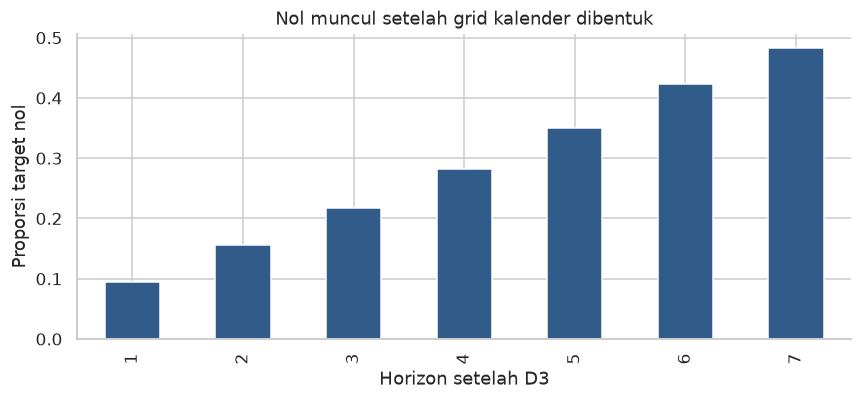

In [9]:
audit=pd.DataFrame({'pemeriksaan':['tiket nol pada transaksi asli','kunci transaksi duplikat','target grid tanpa transaksi','proporsi target nol'],
    'nilai':[int(data['train'].total_ticket.eq(0).sum()),int(data['train'].duplicated(KEY).sum()),int(historical.target_observed.eq(0).sum()),float(historical.total_ticket.eq(0).mean())]})
display(audit)
missing_dates=pd.date_range(data['train'].date_show.min(),data['train'].date_show.max()).difference(data['train'].date_show.unique())
print('Tanggal tanpa transaksi pada seluruh tabel:',len(missing_dates),'|',missing_dates.strftime('%Y-%m-%d').tolist())
fig,ax=plt.subplots(figsize=(8,3.8));historical.groupby('forecast_horizon').total_ticket.apply(lambda x:x.eq(0).mean()).plot.bar(ax=ax,color=COLORS[0]);ax.set(xlabel='Horizon setelah D3',ylabel='Proporsi target nol',title='Nol muncul setelah grid kalender dibentuk');finish_figure('01_zero_grid')

In [10]:
zero_share=historical.total_ticket.eq(0).mean()

Grid historis mengandung **28.7% target nol** meskipun transaksi asli mencatat 0 baris nol. **Keputusan:** eligibility bergantung pada D3; keberadaan transaksi masa depan tidak dipakai untuk memilih pasangan latih.

Ada **1 tanggal global tanpa pencatatan**: 2025-06-13. Penyebabnya tidak diketahui dari ZIP. **Keputusan:** seluruh window historis dengan konteks atau label melintasi tanggal tersebut dikeluarkan; ketiadaan satu baris film/bioskop pada tanggal yang tercatat di tempat lain tetap dipetakan menjadi nol. Dengan demikian, nol grid tidak menyamakan celah pencatatan global dengan penjualan nol.

### 5.2 Pembukaan Bersama, Keterlambatan, dan Sensor Kiri

**Hipotesis / pertanyaan.** Tanggal transaksi pertama suatu bioskop dapat berbeda dari D1 film, dan film yang sudah tayang saat train dimulai tidak memiliki pembukaan yang teramati.

**Pemeriksaan.** Audit distribusi first_pair_day, observed flags, umur window, serta film yang masuk pada batas awal data.

left_censored,0,1
first_pair_day,,
1,11375,2463
2,1509,2
3,518,6


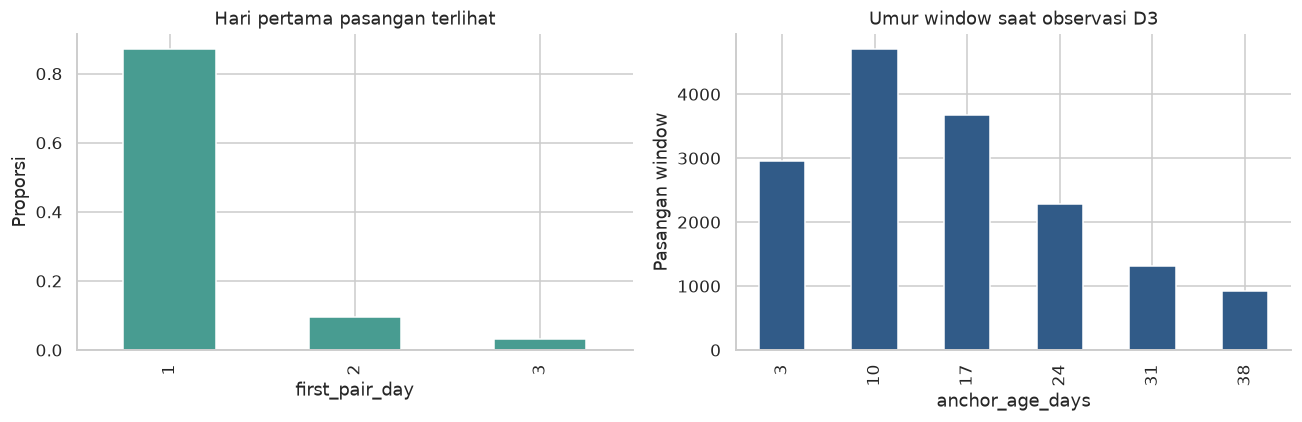

In [11]:
tab=pd.crosstab(opening.first_pair_day,opening.left_censored);display(tab)
fig,axes=plt.subplots(1,2,figsize=(12,4));opening.first_pair_day.value_counts(normalize=True).sort_index().plot.bar(ax=axes[0],color=COLORS[1]);axes[0].set(title='Hari pertama pasangan terlihat',ylabel='Proporsi')
opening.anchor_age_days.value_counts().sort_index().plot.bar(ax=axes[1],color=COLORS[0]);axes[1].set(title='Umur window saat observasi D3',ylabel='Pasangan window');finish_figure('02_opening_alignment')

Sebanyak **12.8% pasangan window** baru muncul setelah D1. Flag sensor kiri mencakup **15.6% pasangan window**. **Keputusan:** tanggal pembukaan diselaraskan per film; nol sebelum transaksi pertama tetap masuk skala resmi, sementara observed flags dan sensor kiri menjadi fitur diagnostik.

### 5.3 Skala, Heavy Tail, dan Bobot MASE

**Hipotesis / pertanyaan.** Skala tiket sangat heterogen; kesalahan relatif pada pasangan kecil dapat lebih penting daripada volume nasional.

**Pemeriksaan.** Periksa kuantil, konsentrasi tiket, skala log, dan distribusi bobot 1/scale.

,opening scale
count,15873.000000
mean,395.033915
std,715.835107
min,1.000000
1%,9.000000
10%,44.333333
50%,196.000000
90%,864.866667
95%,1367.600000
99%,3228.146667


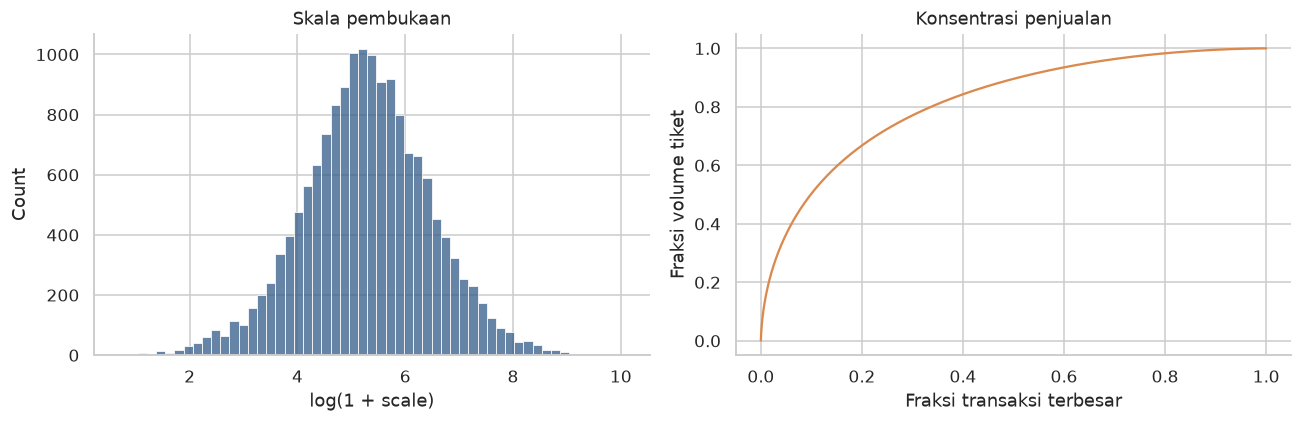

In [12]:
display(opening.scale.describe(percentiles=[.01,.1,.5,.9,.95,.99]).to_frame('opening scale'))
v=np.sort(data['train'].total_ticket.to_numpy())[::-1]
fig,axes=plt.subplots(1,2,figsize=(12,4));sns.histplot(np.log1p(opening.scale),bins=55,ax=axes[0],color=COLORS[0]);axes[0].set(xlabel='log(1 + scale)',title='Skala pembukaan')
axes[1].plot(np.arange(1,len(v)+1)/len(v),np.cumsum(v)/v.sum(),color=COLORS[2]);axes[1].set(xlabel='Fraksi transaksi terbesar',ylabel='Fraksi volume tiket',title='Konsentrasi penjualan');finish_figure('03_scale_tail')

Median skala pembukaan adalah **196.00**, sedangkan persentil 99 mencapai **3228.15**. **Keputusan:** loss dihitung dalam satuan MASE; fitur skala memakai transformasi log dan hasil juga dilaporkan per rentang skala.

### 5.4 Perkembangan Penjualan dan Struktur Kalender

**Hipotesis / pertanyaan.** Pertumbuhan kumulatif dan penurunan harian menunjukkan pola berbeda; kalender dapat mengubah interpretasi tren awal.

**Pemeriksaan.** Bentuk rasio target/scale dan lintasan kumulatif menurut weekday/weekend, tanpa menambah target test.

is_weekend,0,1
forecast_horizon,,
1,0.697547,1.062933
2,0.500000,1.109516
3,0.466523,0.938802
4,0.489256,0.000000
5,0.351273,0.377820
6,0.237197,0.170039
7,0.120283,0.000000


median  count
is_weekend is_holiday                 
0          0           0.416955  75136
           1           0.663021   4229
1          0           0.736449  29621
           1           0.553073   2125

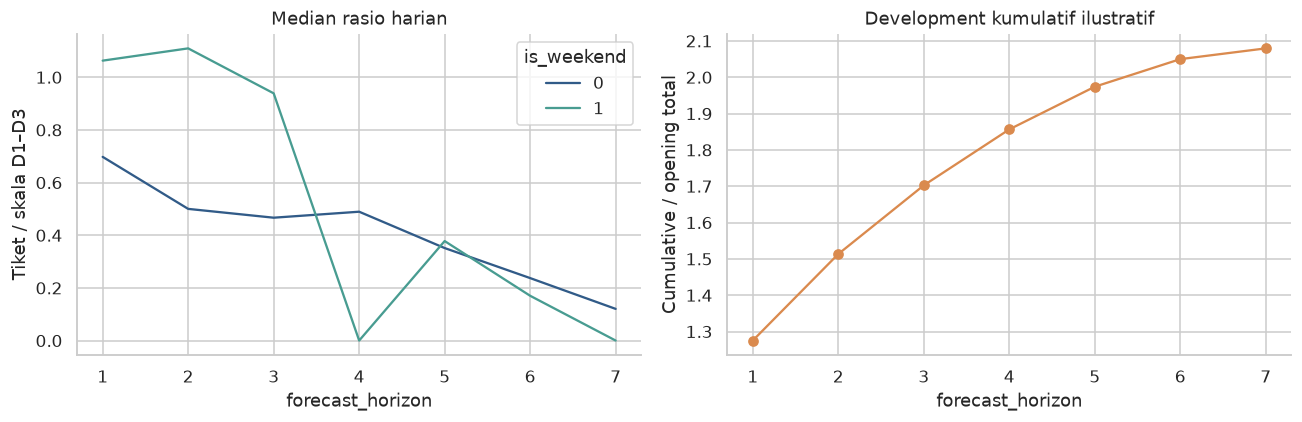

In [13]:
curve=historical.assign(ratio=historical.total_ticket/historical.scale).groupby(['forecast_horizon','is_weekend']).ratio.median().unstack()
display(curve)
display(historical.assign(ratio=historical.total_ticket/historical.scale).groupby(['is_weekend','is_holiday']).ratio.agg(['median','count']))
fig,axes=plt.subplots(1,2,figsize=(12,4));curve.plot(ax=axes[0],color=COLORS[:2]);axes[0].set(title='Median rasio harian',ylabel='Tiket / skala D1–D3')
(1+historical.assign(ratio=historical.total_ticket/historical.scale).groupby('forecast_horizon').ratio.median().cumsum()/3).plot(ax=axes[1],marker='o',color=COLORS[2]);axes[1].set(title='Development kumulatif ilustratif',ylabel='Cumulative / opening total');finish_figure('04_development_calendar')

Kurva kumulatif di atas merangkum data untuk EDA. **Keputusan:** development factors untuk model harus dihitung ulang hanya dari donor yang tersedia sebelum forecast origin; kurva EDA penuh tidak dipakai sebagai prior validasi.

### 5.5 Show, Occupancy, dan Tekstur Pengukuran

**Hipotesis / pertanyaan.** Hubungan tiket dan occupancy dapat dipengaruhi ukuran kapasitas serta pembulatan; show masa depan tidak tersedia saat inferensi.

**Pemeriksaan.** Audit korelasi pembukaan, implied seats, outlier occupancy, dan hubungan perubahan show dengan rasio target.

,implied seats per show
count,138722.000000
mean,164.979042
std,144.032136
min,21.346470
1%,40.061361
50%,150.447257
99%,428.545976
max,15576.923077


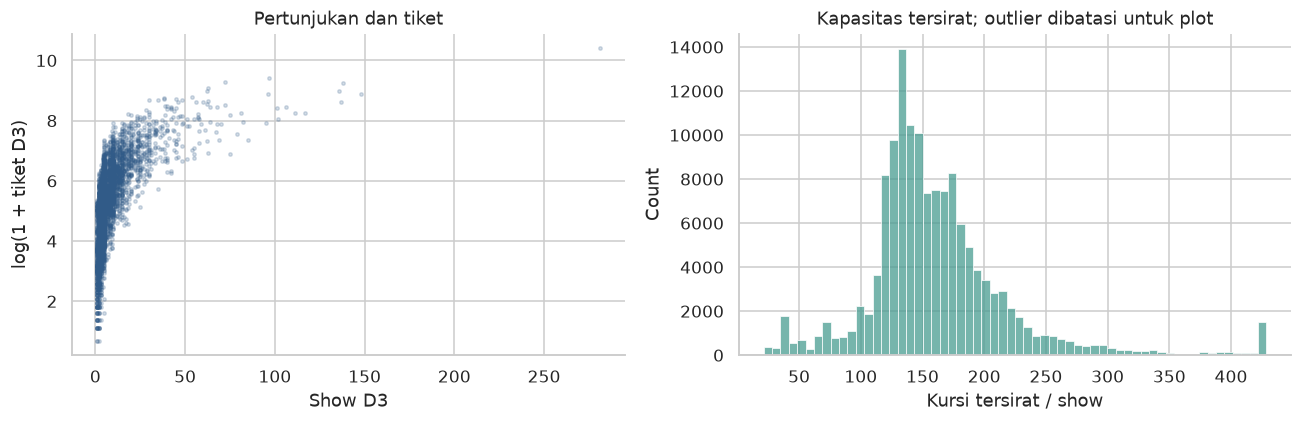

In [14]:
t=data['train'];mask=t.occupation_rate.gt(0)&t.total_show.gt(0)
seats=t.loc[mask,'total_ticket']/(t.loc[mask,'occupation_rate']/100*t.loc[mask,'total_show'])
display(seats.describe(percentiles=[.01,.5,.99]).to_frame('implied seats per show'))
sample=opening.sample(min(5000,len(opening)),random_state=42)
fig,axes=plt.subplots(1,2,figsize=(12,4));axes[0].scatter(sample.show_d3,np.log1p(sample.ticket_d3),s=5,alpha=.2,color=COLORS[0]);axes[0].set(xlabel='Show D3',ylabel='log(1 + tiket D3)',title='Pertunjukan dan tiket')
sns.histplot(seats.clip(upper=seats.quantile(.99)),bins=60,ax=axes[1],color=COLORS[1]);axes[1].set(title='Kapasitas tersirat; outlier dibatasi untuk plot',xlabel='Kursi tersirat / show');finish_figure('05_occupancy_show')

Occupancy di luar 0–100 ditemukan pada **0 transaksi**. Kapasitas tersirat juga mencampur pembulatan dan agregasi bioskop. **Keputusan:** hanya show dan occupancy D1–D3 dipakai; kuantitas ini tidak diperlakukan sebagai kapasitas kursi yang sudah terverifikasi.

### 5.6 Heterogenitas Genre, Kota, dan Alokasi Bioskop

**Hipotesis / pertanyaan.** Pola pembukaan film dan pangsa bioskop tidak dapat dirangkum oleh satu tingkat permintaan nasional.

**Pemeriksaan.** Bandingkan median skala genre, variasi kota, dan perubahan pangsa pasangan dalam tiga hari.

,median,count
genre_primary,,
Horror,211.333333,4755
Drama,205.166667,3772
Action,200.000000,2040
Animation,287.500000,1544
Comedy,143.666667,746
Thriller,88.666667,546
Adventure,153.000000,453
War,184.000000,441
Mystery,409.500000,400


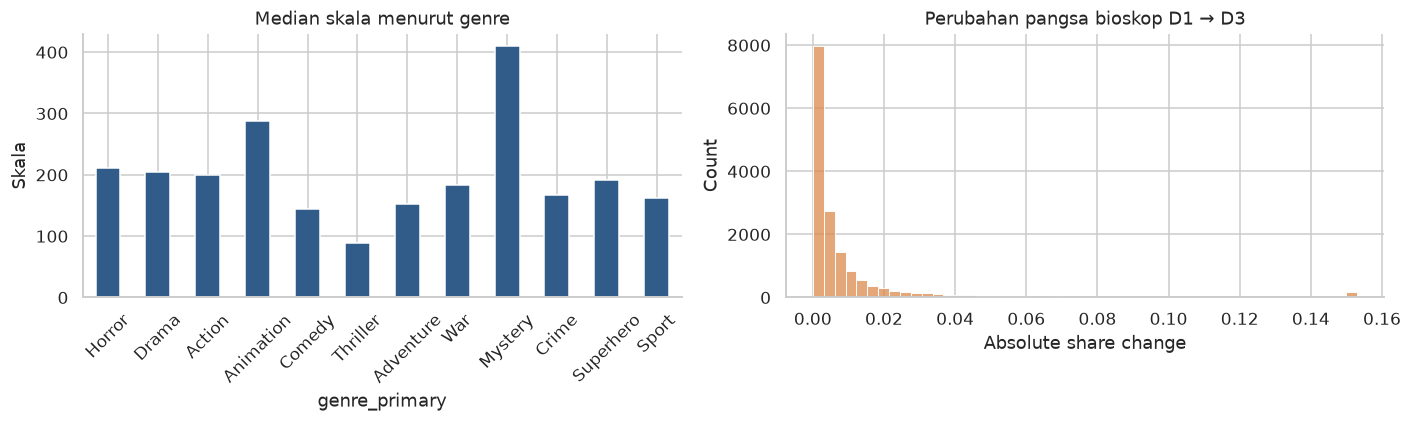

In [15]:
genre=opening.groupby('genre_primary').scale.agg(['median','count']).sort_values('count',ascending=False).head(12);display(genre)
fig,axes=plt.subplots(1,2,figsize=(13,4));genre['median'].plot.bar(ax=axes[0],color=COLORS[0]);axes[0].set(title='Median skala menurut genre',ylabel='Skala');axes[0].tick_params(axis='x',rotation=45)
delta=(opening.pair_share_d3-opening.pair_share_d1).abs();sns.histplot(delta.clip(upper=delta.quantile(.99)),bins=50,ax=axes[1],color=COLORS[2]);axes[1].set(title='Perubahan pangsa bioskop D1 → D3',xlabel='Absolute share change');finish_figure('06_heterogeneity')

Median perubahan absolut pangsa bioskop D1–D3 adalah **0.0030**. **Keputusan:** konteks film dan pasangan dipertahankan bersama; prior genre dan bioskop mengalami shrinkage menuju kelompok besar ketika bukti sedikit.

### 5.7 Penghentian Tayang dan Alasan Hurdle

**Hipotesis / pertanyaan.** Penurunan jumlah pertunjukan pembukaan meningkatkan risiko target nol, terutama pada horizon lebih jauh.

**Pemeriksaan.** Periksa proporsi nol menurut arah show dan horizon, dengan denominator kelompok ditampilkan.

mean  count
forecast_horizon show_state                 
1                menurun     0.126606   5837
                 tetap/naik  0.077023  10036
2                menurun     0.200617   5837
                 tetap/naik  0.130829  10036
3                menurun     0.265719   5837
                 tetap/naik  0.189418  10036
4                menurun     0.326880   5837
                 tetap/naik  0.255082  10036
5                menurun     0.406202   5837
                 tetap/naik  0.317358  10036
6                menurun     0.482782   5837
                 tetap/naik  0.389199  10036
7                menurun     0.577694   5837
                 tetap/naik  0.426863  10036

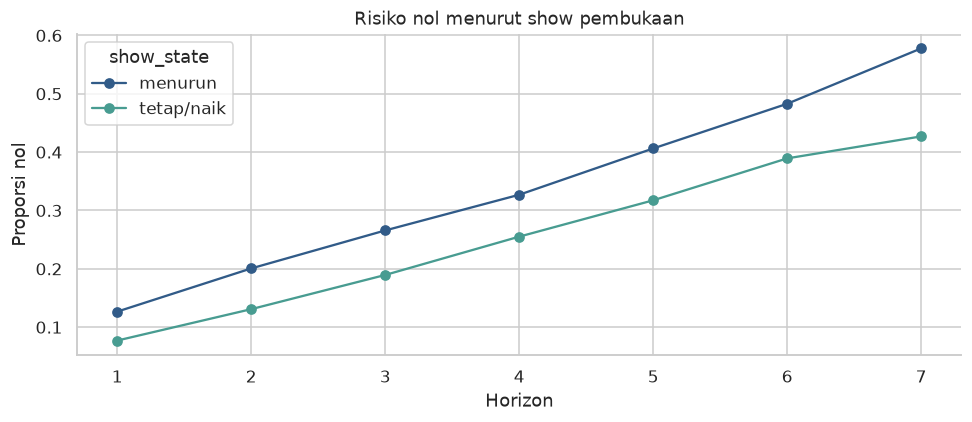

In [16]:
z=historical.assign(show_state=np.where(historical.show_d3<historical.show_d1,'menurun','tetap/naik'),zero=historical.total_ticket.eq(0))
table=z.groupby(['forecast_horizon','show_state']).zero.agg(['mean','count']);display(table)
fig,ax=plt.subplots(figsize=(9,4));table['mean'].unstack().plot(ax=ax,marker='o',color=COLORS[:2]);ax.set(ylabel='Proporsi nol',xlabel='Horizon',title='Risiko nol menurut show pembukaan');finish_figure('07_hurdle_risk')

Pola ini mendukung pengujian hurdle, tetapi tidak membuktikan penghentian tayang sebagai satu-satunya penyebab nol. **Keputusan:** classifier peluang nol dan distribusi tiket positif dibandingkan dengan regresi langsung; pemenang dipilih melalui prediksi historis di luar sampel.

### 5.8 Pergeseran Train–Test dan Adversarial Validation

**Hipotesis / pertanyaan.** Distribusi pembukaan test dapat berbeda dari contoh latih; split per baris memberikan keyakinan palsu karena satu film muncul di banyak pasangan.

**Pemeriksaan.** Bandingkan ECDF skala dan first_pair_day; lakukan classifier domain pada pemisahan film, bukan pemisahan pasangan acak.

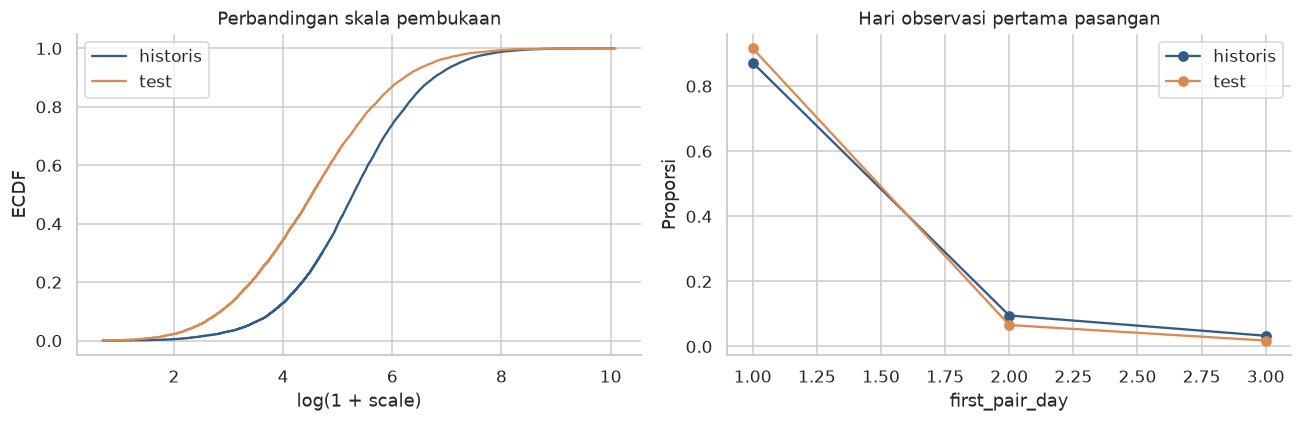

In [17]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,f,color in [('historis',opening,COLORS[0]),('test',test_opening,COLORS[2])]:
    v=np.sort(f.scale.to_numpy());axes[0].plot(np.log1p(v),np.arange(1,len(v)+1)/len(v),label=name,color=color)
    f.first_pair_day.value_counts(normalize=True).sort_index().plot(ax=axes[1],marker='o',label=name,color=color)
axes[0].set(xlabel='log(1 + scale)',ylabel='ECDF',title='Perbandingan skala pembukaan');axes[0].legend();axes[1].set(title='Hari observasi pertama pasangan',ylabel='Proporsi');axes[1].legend();finish_figure('08_shift')


AUC domain dengan pemisahan film adalah **0.7535**. AUC mengukur keterbedaan input, bukan akurasi target. **Keputusan:** evaluasi kronologis dan cold-film dipertahankan; hasil menurut skala dan keterlambatan pembukaan perlu dibaca bersama skor keseluruhan.

### 5.9 Audit Sumber Eksternal dan Batas Transfer

**Hipotesis / pertanyaan.** Sumber nasional historis memiliki cakupan kecil dan satuan berbeda; prior eksternal harus memiliki pengaruh terbatas.

**Pemeriksaan.** Audit jenis metrik, sumber, available_at, dan judul yang cocok dengan metadata resmi.

,records,sources
metric,,
cumulative_admissions,32,6
daily_admissions,41,7
daily_showtimes,24,4
reported_film_admissions,40,1


,available_at,source_updated_at
min,2025-01-22 09:48:04+00:00,2025-01-22 07:04:07+00:00
max,2025-09-09 14:00:00+00:00,2025-09-09 14:00:00+00:00


train_title_matches         27
test_title_matches           0
metadata_matched_records    75
dtype: int64

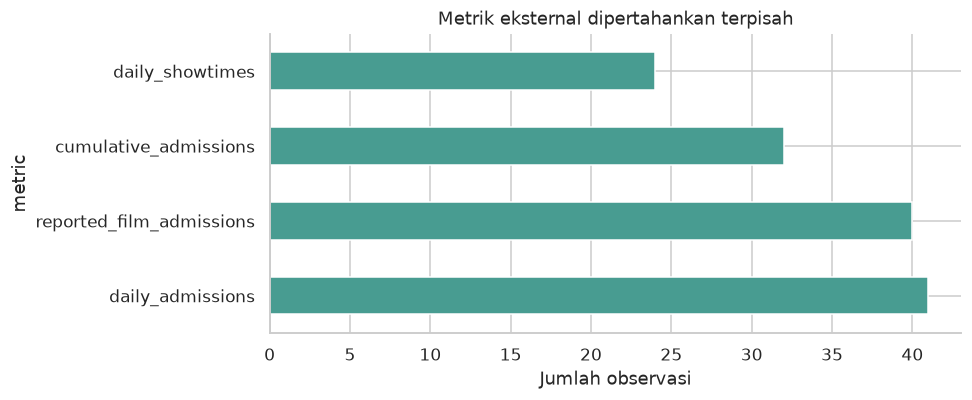

In [18]:
display(external.groupby('metric').agg(records=('value','size'),sources=('source_id','nunique')))
display(external[['available_at','source_updated_at']].agg(['min','max']))
train_keys=set(data['train'].movie_title.map(title_key));test_keys=set(data['test'].movie_title.map(title_key));ext_keys=set(external.title_key)
coverage={'train_title_matches':len(train_keys&ext_keys),'test_title_matches':len(test_keys&ext_keys),'metadata_matched_records':int(external.genre_primary.notna().sum())};display(pd.Series(coverage))
fig,ax=plt.subplots(figsize=(9,3.8));external.metric.value_counts().plot.barh(ax=ax,color=COLORS[1]);ax.set(xlabel='Jumlah observasi',title='Metrik eksternal dipertahankan terpisah');finish_figure('09_external_scope')

Arsip berisi **137 observasi dari 8 sumber**, dengan **0 kecocokan judul test langsung**. **Keputusan:** data dipakai untuk prior genre yang mengalami shrinkage, dengan kontribusi 5%; admissions nasional tidak menjadi label bioskop dan ketiadaan observasi tidak dianggap nol.

### 5.10 Scorecard Kebocoran dan Kontrak Desain

**Hipotesis / pertanyaan.** Kebocoran dapat muncul melalui future eligibility, target encoding, kalender salah, atau pemilihan gate pada label periode yang sedang dinilai.

**Pemeriksaan.** Hubungkan bukti EDA dengan invariant pipeline dan ablation yang dapat menyangkal hipotesis model.

In [19]:
design=pd.DataFrame([
['Transaksi positif saja','D3 eligibility + grid nol','hurdle vs direct'],
['Pembukaan bertahap','observed flags + first_pair_day','slice menurut first_pair_day'],
['Skala heavy tail','MASE + log scale','slice menurut scale'],
['Perkembangan tidak tetap','rolling development + credibility','tanpa fitur aktuaria'],
['Show berubah','fitur D1–D3 saja','slice arah show dan horizon'],
['Heterogenitas film/lokasi','prior kelompok dengan shrinkage','prior NB tanpa koreksi'],
['Film baru dan shift kalender','chronological cold-film folds','hasil bulanan'],
['Cakupan eksternal terbatas','as-of availability + bobot 5%','tanpa eksternal'],
['Risiko gate menghafal','hanya earlier OOF + film purge','gate statis vs learned']],
columns=['Bukti / risiko','Keputusan preprocessing atau model','Pengujian'])
display(design);design.to_csv(OUTPUT/'eda_design_contract.csv',index=False)

,Bukti / risiko,Keputusan preprocessing atau model,Pengujian
0,Transaksi positif saja,D3 eligibility + grid nol,hurdle vs direct
1,Pembukaan bertahap,observed flags + first_pair_day,slice menurut first_pair_day
2,Skala heavy tail,MASE + log scale,slice menurut scale
3,Perkembangan tidak tetap,rolling development + credibility,tanpa fitur aktuaria
4,Show berubah,fitur D1–D3 saja,slice arah show dan horizon
5,Heterogenitas film/lokasi,prior kelompok dengan shrinkage,prior NB tanpa koreksi
6,Film baru dan shift kalender,chronological cold-film folds,hasil bulanan
7,Cakupan eksternal terbatas,as-of availability + bobot 5%,tanpa eksternal
8,Risiko gate menghafal,hanya earlier OOF + film purge,gate statis vs learned


Scorecard ini menjadi kontrak desain. Temuan yang tidak konsisten antarperiode akan dibahas sebagai keterbatasan, bukan dipakai sebagai alasan memilih model secara retrospektif.

## 6. Preprocessing dan Feature Engineering

Untuk pasangan film–bioskop, skala resmi adalah
$$s_p=\max\left((y_1+y_2+y_3)/3,1\right).$$
Tanggal pembukaan diselaraskan per film. Pasangan donor dipilih dari observasi D3 sebelum melihat target masa depan. Label yang tidak tercatat di tujuh tanggal target menjadi nol menurut kontrak kompetisi. Format judul dipertahankan untuk prediksi; judul dasar dipakai untuk purge film.

Prior kelompok dipelajari dari donor yang label D10-nya sudah selesai sebelum forecast origin. Median rasio perkembangan memiliki shrinkage menurut genre dan bioskop. Credibility menggunakan exposure pembukaan dan estimasi variasi dalam/antar kelompok. Bentuk ini merupakan adaptasi empiris, bukan estimasi posterior asuransi yang sudah terbukti untuk tiket.

Eksternal membentuk ranking relatif **di dalam sumber, metrik, dan periode laporan yang sama**. Ranking genre mengalami shrinkage dengan jumlah bukti. Sinyal digabung melalui `0.95 + 0.05 × signal`; model tidak menerima target nasional masa depan. Availability diperiksa untuk setiap forecast origin, termasuk contoh latih.

In [20]:
CAT_COLUMNS=['cinema_ids','city_name','genre_primary','age_rating','movie_format']
BASE_NUMERIC=['forecast_horizon','anchor_age_days','log_scale','context_days','first_pair_day','ticket_cv',
    'ticket_ratio_3_1','ticket_ratio_3_2','show_ratio_3_1','occ_delta','movie_context_cinemas',
    'movie_ratio_3_1','pair_vs_movie_trend','dow','is_weekend','is_holiday','context_holidays',
    'context_dow1','context_dow2','context_dow3','ticket_price','genre_count','cast_count','left_censored']
BASE_NUMERIC += [f'{p}_d{d}' for p in ['ticket','ticket_rel','show','occ','observed','tickets_per_show','movie_ticket','movie_show','pair_share'] for d in [1,2,3]]
ACT_COLUMNS=['credibility','development_factor','genre_rate','cinema_rate','individual_ratio','collective_ratio','prior_ratio']

def fit_actuarial_state(train):
    if len(train)==0:return dict(profile=[1.]*7,k=100.,genre={},cinema={})
    ratio=(train.total_ticket/train.scale).clip(0,20)
    t=train.assign(_ratio=ratio)
    profile=t.groupby('forecast_horizon')._ratio.median().reindex(range(1,8)).fillna(1).clip(.02,10)
    # Bühlmann-inspired exposure shrinkage; this is an empirical ticket adaptation.
    pair=t.groupby(['base_movie_title','cinema_ids'])._ratio.agg(['mean','var'])
    within=float(pair['var'].median()) if pair['var'].notna().any() else 1.
    between=max(float(pair['mean'].var()),.01)
    k=float(np.clip(3*train.scale.median()*within/between,10,500))
    genre={};cinema={}
    for col,dest in [('genre_primary',genre),('cinema_ids',cinema)]:
        temp=t.assign(_relative=t._ratio/profile.reindex(t.forecast_horizon).to_numpy()).groupby(col)._relative.agg(['median','count'])
        for name,row in temp.iterrows():
            z=row['count']/(row['count']+200)
            dest[str(name)]=float(np.clip(1+z*(row['median']-1),.2,3))
    return dict(profile=profile.to_list(),k=k,genre=genre,cinema=cinema)

def external_signals(query,external):
    result=np.ones(len(query));coverage=np.zeros(len(query),int)
    for anchor,idx in query.groupby('anchor_date').groups.items():
        # All rows, including training examples, respect their own forecast origin.
        asof=pd.Timestamp(anchor).tz_localize('Asia/Jakarta')+pd.Timedelta(days=1)-pd.Timedelta(seconds=1)
        e=external.loc[external.available_at.le(asof.tz_convert('UTC')) & external.genre_primary.notna()].copy()
        e=e.loc[e.metric.ne('daily_showtimes')]
        if e.empty:continue
        # Rank only within a source, metric and reported period. Units are never pooled.
        groupby=e.groupby(['source_id','metric','reported_period'],dropna=False)
        e['rank_signal']=groupby.value.rank(pct=True)
        e.loc[groupby.value.transform('size').eq(1),'rank_signal']=.5
        group=e.groupby('genre_primary').rank_signal.agg(['mean','count'])
        signals=1+(group['count']/(group['count']+10))*(group['mean']-.5)
        result[idx]=query.loc[idx,'genre_primary'].map(signals).fillna(1).to_numpy()
        coverage[idx]=query.loc[idx,'genre_primary'].isin(signals.index).astype(int)
    return result,coverage

def apply_actuarial(query,state,external):
    q=query.reset_index(drop=True).copy();h=q.forecast_horizon.to_numpy(int)
    profile=np.asarray(state['profile']);curve=profile[h-1]
    level=(.5*q.ticket_d3+.5*q.scale).to_numpy(float)
    slope=np.clip(np.log((q.ticket_d3+1)/(q.ticket_d1+1))/2,-.35,.35)
    individual=np.maximum(level*np.exp(slope.to_numpy()*np.minimum(h,3)*.35),0)
    genre=q.genre_primary.map(state['genre']).fillna(1).to_numpy(float)
    cinema=q.cinema_ids.map(state['cinema']).fillna(1).to_numpy(float)
    collective=q.scale.to_numpy()*curve*genre*cinema
    z=(3*q.scale/(3*q.scale+state['k'])).to_numpy()
    prior=np.maximum(z*individual+(1-z)*collective,.1)
    q['credibility']=z;q['development_factor']=1+np.cumsum(profile)[h-1]/3
    q['genre_rate']=genre;q['cinema_rate']=cinema
    q['individual']=individual;q['collective']=collective;q['reference']=prior
    for name,val in [('individual_ratio',individual),('collective_ratio',collective),('prior_ratio',prior)]:q[name]=val/q.scale.to_numpy()
    sig,cov=external_signals(q,external);q['external_signal']=sig;q['external_covered']=cov
    q['external_factor']=.95+.05*sig
    return q

def expanding_features(train,external):
    # Priors for each donor use only windows whose complete label horizon has ended.
    parts=[]
    for anchor,g in train.groupby('anchor_date',sort=True):
        earlier=train.loc[(train.anchor_date+pd.Timedelta(days=7)).lt(anchor)]
        earlier=earlier.loc[~earlier.base_movie_title.isin(g.base_movie_title)]
        parts.append(apply_actuarial(g,fit_actuarial_state(earlier),external))
    return pd.concat(parts,ignore_index=True)

def split_fold(windows,start,end):
    start,end=pd.Timestamp(start),pd.Timestamp(end)
    valid=windows.loc[~windows.is_test & windows.first_seen.ge(start)&windows.first_seen.lt(end)&windows.anchor_age_days.eq(3)].copy()
    train=windows.loc[~windows.is_test & (windows.anchor_date+pd.Timedelta(days=7)).lt(start)].copy()
    train=train.loc[~train.base_movie_title.isin(valid.base_movie_title)].copy()
    assert len(train)>0 and len(valid)>0
    assert train.date_show.max()<start
    assert not set(train.base_movie_title)&set(valid.base_movie_title)
    return train.reset_index(drop=True),valid.reset_index(drop=True)

Pada contoh validasi September, prior eksternal tersedia untuk **35.2% baris**. Faktor eksternal berada pada **0.9979–1.0068**; pengaruh aktual diperiksa lagi melalui ablation.

## 7. Pendekatan 1 — Actuarial Features + LightGBM

Regresi langsung mempelajari `target / reference` dengan sample weight `reference / scale`, sehingga weighted absolute loss setara MASE. Pembanding hurdle memperkirakan peluang nol dan kuantil distribusi positif. Median campuran adalah nol jika massa nol sedikitnya 0,5; selain itu kuantil positif yang dibutuhkan adalah
$$q_+=\frac{0.5-p_0}{1-p_0}.$$
Kuantil diproyeksikan menjadi monoton sebelum interpolasi. Semua category levels hanya berasal dari donor; kategori baru menjadi missing pada model pohon. Head untuk setiap fold dipilih dari hasil fold yang lebih awal, dengan hurdle sebagai default saat belum tersedia sejarah OOF.

In [21]:
def tree_schema(train,actuarial=True):
    columns=BASE_NUMERIC+(ACT_COLUMNS if actuarial else [])+CAT_COLUMNS
    return dict(columns=columns,categories={c:sorted(train[c].unique().tolist()) for c in CAT_COLUMNS})

def tree_matrix(frame,schema):
    x=frame[schema['columns']].copy()
    for c in x:
        if c in schema['categories']:
            levels=schema['categories'][c];x[c]=pd.Categorical(x[c].where(x[c].isin(levels),None),categories=levels)
        else:x[c]=pd.to_numeric(x[c],errors='coerce').replace([np.inf,-np.inf],np.nan).fillna(0).astype('float32')
    return x

def mixture_median(p0,q):
    q=np.maximum(np.sort(q,axis=1),0)
    tau=np.clip((.5-p0)/np.maximum(1-p0,1e-9),0,.5)
    right=np.clip(np.searchsorted(QUANTILES,tau),1,len(QUANTILES)-1);left=right-1
    f=np.clip((tau-QUANTILES[left])/(QUANTILES[right]-QUANTILES[left]),0,1);i=np.arange(len(p0))
    return np.where(p0>=.5,0,q[i,left]*(1-f)+q[i,right]*f)

def tree_predict(query,folder):
    folder=Path(folder);s=json.loads((folder/'schema.json').read_text());x=tree_matrix(query,s)
    pred=lambda n:lgb.Booster(model_file=str(folder/(n+'.txt'))).predict(x,num_threads=THREADS)
    p0=np.clip(pred('zero'),0,1);q=np.column_stack([pred(f'q{t:.2f}') for t in QUANTILES])
    return dict(direct=np.maximum(pred('direct'),0)*query.reference.to_numpy(),
                hurdle=mixture_median(p0,q)*query.reference.to_numpy(),p0=p0)

def fit_tree(train,query,folder,seed,actuarial=True,iterations=300):
    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True);s=tree_schema(train,actuarial)
    write_json(folder/'schema.json',s);x=tree_matrix(train,s)
    y=train.total_ticket.to_numpy()/train.reference.to_numpy()
    w=train.reference.to_numpy()/train.scale.to_numpy()
    params=dict(n_estimators=iterations,learning_rate=.04,num_leaves=31,min_child_samples=100,
                reg_lambda=8.,reg_alpha=.1,colsample_bytree=.9,max_bin=127,n_jobs=THREADS,
                verbosity=-1,random_state=seed,deterministic=True,force_col_wise=True)
    for name in ['direct','zero']+[f'q{t:.2f}' for t in QUANTILES]:
        mask=np.ones(len(y),bool)
        if name=='zero':
            m=lgb.LGBMClassifier(objective='binary',**params);target=(y==0).astype(int)
        elif name=='direct':m=lgb.LGBMRegressor(objective='regression_l1',**params);target=y
        else:
            mask=y>0;m=lgb.LGBMRegressor(objective='quantile',alpha=float(name[1:]),**params);target=y
        m.fit(x.loc[mask],target[mask],sample_weight=w[mask])
        m.booster_.save_model(str(folder/(name+'.txt')))
    write_json(folder/'receipt.json',dict(seed=seed,rows=len(train),latest_label=str(train.date_show.max()),
        actuarial=actuarial,parameters=params,label_sha256=hashlib.sha256(train.total_ticket.to_numpy().tobytes()).hexdigest()))
    return tree_predict(query,folder)

## 8. Pendekatan 2 — Negative Binomial Prior + Neural Correction

GLM Negative Binomial memakai link log dan offset `log(reference)`, one-hot kategori donor, serta fitur numerik yang distandarkan pada donor. Dispersion diestimasi dari data latih; optimisasi likelihood memakai regularisasi. Jaringan 64–32 unit mempelajari koreksi
$$\hat y=\mu_{\mathrm{NB}}\exp(f_\theta(x)),$$
dengan layer terakhir berawal dari nol, sehingga prediksi awal sama dengan prior. Koreksi dilatih menggunakan MASE, sehingga keluaran akhirnya merupakan forecast point untuk absolute loss dan tidak diklaim sebagai mean NB terkalibrasi. Jumlah epoch dipilih melalui holdout kronologis internal dengan pemisahan film, kemudian jaringan dilatih ulang pada seluruh donor. Prior NB tanpa koreksi menjadi ablation.

In [22]:
def fit_encoder(train):
    numeric=BASE_NUMERIC+ACT_COLUMNS
    center=train[numeric].replace([np.inf,-np.inf],np.nan).median().fillna(0)
    spread=(train[numeric].replace([np.inf,-np.inf],np.nan).quantile(.75)-train[numeric].quantile(.25)).fillna(1).clip(lower=.1)
    onehot=OneHotEncoder(handle_unknown='ignore',sparse_output=True,dtype=np.float32)
    onehot.fit(train[CAT_COLUMNS])
    return dict(numeric=numeric,center=center.to_dict(),spread=spread.to_dict(),
                cats={c:v.tolist() for c,v in zip(CAT_COLUMNS,onehot.categories_)})

def encoded(frame,encoder):
    c=encoder['numeric'];num=frame[c].replace([np.inf,-np.inf],np.nan).fillna(pd.Series(encoder['center']))
    a=np.clip((num.to_numpy()-np.array([encoder['center'][n] for n in c]))/
              np.array([encoder['spread'][n] for n in c]),-10,10).astype('float32')
    columns=[];codes=[];offset=1+len(c)
    for col,levels in encoder['cats'].items():
        values=frame[col].where(frame[col].isin(levels),None)
        k=pd.Categorical(values,categories=levels).codes.astype(np.int64);ok=k>=0
        columns.extend((k[ok]+offset).tolist());codes.extend(np.flatnonzero(ok).tolist());offset+=len(levels)
    cat=sparse.csr_matrix((np.ones(len(columns),np.float32),(codes,columns)),shape=(len(frame),offset))
    base=sparse.hstack([np.ones((len(frame),1),np.float32),sparse.csr_matrix(a),
                       sparse.csr_matrix((len(frame),offset-1-len(c)))],format='csr')
    return base+cat,a

def fit_nb(train,folder):
    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True);encoder=fit_encoder(train)
    x,_=encoded(train,encoder);y=train.total_ticket.to_numpy(float);ref=train.reference.to_numpy(float)
    alpha=float(np.clip(np.mean(np.clip(((y-ref)**2-ref)/np.maximum(ref**2,1),0,20)),.01,10))
    offset=np.log(np.maximum(ref,.1));ridge=.01
    def objective(beta):
        raw_eta=offset+x@beta;eta=np.clip(raw_eta,-8,16);mu=np.exp(eta)
        active=(raw_eta>-8)&(raw_eta<16)
        loss=float(np.mean(-y*eta+(y+1/alpha)*np.log1p(alpha*mu)))+ridge*np.sum(beta[1:]**2)/2
        g=np.asarray(x.T@(((mu-y)/(1+alpha*mu))*active))/len(y);g[1:]+=ridge*beta[1:]
        return loss,g
    fit=minimize(objective,np.zeros(x.shape[1]),jac=True,method='L-BFGS-B',options={'maxiter':600,'ftol':1e-8})
    if not np.isfinite(fit.x).all():raise ValueError('GLM tidak finite')
    np.savez_compressed(folder/'coefficients.npz',beta=fit.x,alpha=alpha)
    write_json(folder/'encoder.json',encoder)
    write_json(folder/'receipt.json',dict(iterations=int(fit.nit),optimizer_success=bool(fit.success),
        optimizer_message=str(fit.message),gradient_inf_norm=float(np.max(np.abs(fit.jac))),
        alpha=alpha,rows=len(y),log_link=True,offset='log actuarial reference',ridge=ridge,
        maximum_iterations=600,gradient_respects_log_mean_clipping=True))
    return encoder,fit.x

def nb_predict(query,folder):
    folder=Path(folder);e=json.loads((folder/'encoder.json').read_text());x,_=encoded(query,e)
    b=np.load(folder/'coefficients.npz')['beta']
    return np.exp(np.clip(np.log(query.reference.to_numpy())+x@b,-8,16))

In [23]:
class CorrectionNetwork(nn.Module):
    def __init__(self,n):
        super().__init__();self.net=nn.Sequential(nn.Linear(n,64),nn.ReLU(),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,1))
        nn.init.zeros_(self.net[-1].weight);nn.init.zeros_(self.net[-1].bias)
    def forward(self,x,prior):return prior*torch.exp(self.net(x).squeeze(-1).clamp(-4,4))

def inner_split(frame):
    anchors=np.sort(frame.anchor_date.unique());cut=pd.Timestamp(anchors[int(len(anchors)*.75)])
    va=frame.anchor_date.ge(cut).to_numpy()
    films=set(frame.loc[va,'base_movie_title'])
    tr=((frame.anchor_date+pd.Timedelta(days=7)).lt(cut)&~frame.base_movie_title.isin(films)).to_numpy()
    if tr.sum()<200 or va.sum()<100: return None
    assert frame.loc[tr,'date_show'].max()<cut
    return np.flatnonzero(tr),np.flatnonzero(va)

def optimize_network(model,x,prior,y,scale,seed,epochs=32,validation=None):
    torch.manual_seed(seed);rng=np.random.default_rng(seed);model=model.to(DEVICE)
    tensors=[torch.tensor(a,dtype=torch.float32,device=DEVICE) for a in [x,prior,y,scale]]
    xx,pp,yy,ss=tensors;optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.01)
    best=None;bestscore=float('inf');bestepoch=epochs;stale=0
    train_idx=np.arange(len(y)) if validation is None else validation[0]
    for epoch in range(epochs):
        model.train()
        for idx in np.array_split(rng.permutation(train_idx),max(1,int(np.ceil(len(train_idx)/2048)))):
            optimizer.zero_grad();p=model(xx[idx],pp[idx]);loss=torch.mean(torch.abs(p-yy[idx])/ss[idx]);loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5);optimizer.step()
        if validation is not None:
            model.eval();idx=validation[1]
            with torch.no_grad():score=float(torch.mean(torch.abs(model(xx[idx],pp[idx])-yy[idx])/ss[idx]).cpu())
            if score<bestscore-1e-5:
                bestscore=score;best={k:v.detach().cpu().clone() for k,v in model.state_dict().items()};bestepoch=epoch+1;stale=0
            else:stale+=1
            if stale>=6:break
    if best is not None:model.load_state_dict(best)
    return model.cpu(),bestepoch

def fit_correction(train,query,folder,seed,external):
    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True)
    split=inner_split(train);epochs=24
    if split is not None:
        a,b=split;inner=folder/'inner';fit_nb(train.iloc[a],inner)
        held=apply_actuarial(train.iloc[b],fit_actuarial_state(train.iloc[a]),external)
        inner_data=pd.concat([train.iloc[a],held],ignore_index=True)
        inner_indices=(np.arange(len(a)),np.arange(len(a),len(a)+len(b)))
        enc=json.loads((inner/'encoder.json').read_text())
        _,x=encoded(inner_data,enc);prior=nb_predict(inner_data,inner)
        torch.manual_seed(seed);m=CorrectionNetwork(x.shape[1])
        _,epochs=optimize_network(m,x,prior,inner_data.total_ticket.to_numpy(),inner_data.scale.to_numpy(),seed,40,inner_indices)
        write_json(inner/'split_audit.json',dict(latest_donor_label=str(train.iloc[a].date_show.max()),
            earliest_validation_origin=str(train.iloc[b].anchor_date.min()),held_film_overlap=0,
            validation_prior_frozen=True))
    fit_nb(train,folder/'nb');enc=json.loads((folder/'nb/encoder.json').read_text())
    _,x=encoded(train,enc);prior=nb_predict(train,folder/'nb')
    torch.manual_seed(seed);m=CorrectionNetwork(x.shape[1])
    model,_=optimize_network(m,x,prior,train.total_ticket.to_numpy(),train.scale.to_numpy(),seed,epochs)
    torch.save(model.state_dict(),folder/'network.pt')
    write_json(folder/'network.json',dict(seed=seed,input_dim=x.shape[1],hidden=[64,32],epochs=epochs,
        inner_temporal_split=split is not None,loss='mean absolute error / opening scale',device=DEVICE))
    return correction_predict(query,folder)

def correction_predict(query,folder):
    folder=Path(folder);enc=json.loads((folder/'nb/encoder.json').read_text())
    _,x=encoded(query,enc);prior=nb_predict(query,folder/'nb')
    m=CorrectionNetwork(x.shape[1]);m.load_state_dict(torch.load(folder/'network.pt',map_location='cpu',weights_only=True));m.eval()
    with torch.no_grad():p=m(torch.tensor(x),torch.tensor(prior,dtype=torch.float32)).numpy()
    return dict(cann=np.maximum(p,0),nb=prior)

## 9. Pendekatan 3 — Learned Credibility Mixture

Lima ahli menyediakan regresi langsung, hurdle, koreksi neural, proyeksi individual, dan prior kolektif. Gate kecil 32 unit menghasilkan softmax, sehingga
$$\hat y_i=\sum_k w_k(x_i)\hat y_{ik},\quad w_k\ge0,\quad\sum_kw_k=1.$$
Fitur gate menunjukkan kelengkapan, volume, konsistensi pembukaan, horizon, dan ketidaksetujuan ahli. Gate belajar dari **prediksi OOF periode yang sudah berakhir**, bukan prediksi in-sample atau label fold aktif. Fold pertama memakai bobot statis yang ditentukan sebelum evaluasi. Pembanding statis dipilih dari bank convex weights pada sejarah OOF yang sama.

In [24]:
EXPERTS=['direct','hurdle','cann','individual','collective']
GATE_COLUMNS=['forecast_horizon','log_scale','context_days','first_pair_day','ticket_cv',
              'ticket_ratio_3_1','show_ratio_3_1','occ_delta','credibility','disagreement']

def gate_arrays(frame,components,center=None,spread=None):
    p=np.column_stack([components[n] for n in EXPERTS])/frame.scale.to_numpy()[:,None]
    x=frame[[c for c in GATE_COLUMNS if c!='disagreement']].to_numpy(float)
    x=np.column_stack([x,np.std(p,axis=1)])
    x=np.nan_to_num(x,nan=0,posinf=10,neginf=-10)
    if center is None:center=np.median(x,axis=0);spread=np.maximum(np.quantile(x,.75,axis=0)-np.quantile(x,.25,axis=0),.1)
    return np.clip((x-center)/spread,-10,10).astype('float32'),p.astype('float32'),center,spread

class CredibilityGate(nn.Module):
    def __init__(self,n,weights):
        super().__init__();self.net=nn.Sequential(nn.Linear(n,32),nn.ReLU(),nn.Linear(32,len(EXPERTS)))
        nn.init.zeros_(self.net[-1].weight)
        with torch.no_grad():self.net[-1].bias.copy_(torch.tensor(np.log(np.maximum(weights,1e-3)),dtype=torch.float32))
    def weights(self,x):return torch.softmax(self.net(x),dim=1)
    def forward(self,x,experts):return (self.weights(x)*experts).sum(dim=1)

def static_weights(history,components):
    if history is None or len(history)<200:return np.array([.15,.45,.2,.1,.1])
    p=np.column_stack([components[n] for n in EXPERTS])/history.scale.to_numpy()[:,None]
    y=history.total_ticket.to_numpy()/history.scale.to_numpy()
    candidates=[np.ones(5)/5]+[np.eye(5)[i] for i in range(5)]
    for a in range(5):
        for b in range(a+1,5):
            for w in [.25,.5,.75]:
                q=np.zeros(5);q[a]=w;q[b]=1-w;candidates.append(q)
    return min(candidates,key=lambda w:float(np.abs(p@w-y).mean()))

def fit_gate(history,components,folder,seed):
    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True);weights=static_weights(history,components)
    if history is None or len(history)<200:
        write_json(folder/'gate.json',dict(kind='static_warmup',weights=weights.tolist(),experts=EXPERTS,rows=0));return
    split=inner_split(history);epochs=16
    # The epoch selection only uses earlier OOF labels, with a chronological film purge.
    if split is not None:
        a,b=split;hc={n:components[n][a] for n in EXPERTS};vc={n:components[n][b] for n in EXPERTS}
        warm=static_weights(history.iloc[a],hc)
        xa,pa,ca,sa=gate_arrays(history.iloc[a],hc);xb,pb,_,_=gate_arrays(history.iloc[b],vc,ca,sa)
        inner_data=pd.concat([history.iloc[a],history.iloc[b]],ignore_index=True)
        torch.manual_seed(seed);m=CredibilityGate(xa.shape[1],warm)
        _,epochs=optimize_network(m,np.vstack([xa,xb]),np.vstack([pa,pb]),
            inner_data.total_ticket.to_numpy()/inner_data.scale.to_numpy(),np.ones(len(inner_data)),seed,30,
            (np.arange(len(a)),np.arange(len(a),len(a)+len(b))))
        write_json(folder/'inner_split_audit.json',dict(latest_donor_label=str(history.iloc[a].date_show.max()),
            earliest_validation_origin=str(history.iloc[b].anchor_date.min()),held_film_overlap=0,
            initialization_and_transform_fit_on_inner_train=True))
    x,p,center,spread=gate_arrays(history,components)
    torch.manual_seed(seed);m=CredibilityGate(x.shape[1],weights)
    m,_=optimize_network(m,x,p,history.total_ticket.to_numpy()/history.scale.to_numpy(),np.ones(len(history)),seed,epochs)
    torch.save(m.state_dict(),folder/'network.pt')
    write_json(folder/'gate.json',dict(kind='learned',weights=weights.tolist(),experts=EXPERTS,
        center=center.tolist(),spread=spread.tolist(),input_dim=x.shape[1],epochs=epochs,
        rows=len(history),latest_label=str(history.date_show.max()),seed=seed))

def gate_predict(query,components,folder):
    folder=Path(folder);s=json.loads((folder/'gate.json').read_text());w=np.asarray(s['weights'])
    p=np.column_stack([components[n] for n in EXPERTS]);static=p@w
    if s['kind']=='static_warmup':return dict(prediction=static,static=static,weights=np.tile(w,(len(query),1)))
    x,r,_,_=gate_arrays(query,components,np.asarray(s['center']),np.asarray(s['spread']))
    m=CredibilityGate(s['input_dim'],w);m.load_state_dict(torch.load(folder/'network.pt',map_location='cpu',weights_only=True));m.eval()
    with torch.no_grad():weights=m.weights(torch.tensor(x)).numpy()
    return dict(prediction=np.sum(weights*p,axis=1),static=static,weights=weights)

## 10. Validasi Kronologis, Baseline, dan Ablation

Lima jendela Mei–September menahan film yang baru muncul pada masing-masing bulan. Seluruh window donor harus selesai sebelum awal bulan. Film dasar validasi dikeluarkan dari donor, prior, serta sejarah gate. Statistik headline memakai MASE resmi. Semua bulan ini merupakan periode pengembangan; interval bootstrap tidak menghilangkan bias pemilihan model dari eksplorasi berulang.

Setiap pendekatan dilatih dengan seed 42, 137, dan 2026. Tabel membandingkan model rata-rata seed, prior tanpa koreksi, gate statis, tree tanpa fitur aktuaria, tanpa kontribusi eksternal, dan dua baseline pembukaan.

### Kalibrasi horizon menggunakan prediksi historis di luar sampel

Galat validasi dapat memiliki bias berbeda pada horizon pendek dan panjang. Faktor kalibrasi meminimalkan L1 berskala melalui median berbobot rasio target/prediksi, dengan bobot prediksi/scale. Rasio median dibatasi pada 0,5–1,5 dan mengalami shrinkage $n/(n+1000)$ menuju satu. Faktor setiap fold hanya belajar dari horizon donor OOF yang sudah selesai sebelum cutoff serta mengeluarkan film dasar yang ditahan.

Kalibrasi per horizon dengan shrinkage dipilih melalui eksperimen pengembangan label resmi; kalibrasi global dan horizon tanpa shrinkage menjadi pembanding. Pemilihan ini membuat kelima bulan tetap berstatus data pengembangan. Semua ablation utama mempertahankan faktor baseline masing-masing agar satu komponen diubah setiap kali. Baris `without_calibration_*` menguji dampak pascaproses ini. Gate tetap belajar dari ahli OOF sebelum kalibrasi.

In [25]:
def mase(frame,pred):return float(np.mean(np.abs(frame.total_ticket.to_numpy()-pred)/frame.scale.to_numpy()))

def fit_calibration(history):
    state={}
    for name in ['approach1','approach2','approach3']:
        values=[]
        for horizon in range(1,8):
            h=pd.DataFrame() if history is None else history.loc[history.forecast_horizon.eq(horizon)]
            factor=1.
            if len(h):
                p=h['raw_prediction_'+name].to_numpy();ok=p>1e-8
                if ok.sum()>=100:
                    ratio=h.total_ticket.to_numpy()[ok]/p[ok];weight=p[ok]/h.scale.to_numpy()[ok]
                    idx=np.argsort(ratio);cdf=np.cumsum(weight[idx]);median=ratio[idx[np.searchsorted(cdf,.5*cdf[-1])]]
                    factor=float(1+ok.sum()/(ok.sum()+1000)*(np.clip(median,.5,1.5)-1))
            values.append(factor)
        state[name]=values
    return state

def calibration_multiplier(frame,state,name):
    return np.asarray(state[name])[frame.forecast_horizon.to_numpy(int)-1]

def previous_history(frames,start,held):
    if not frames:return None,{}
    h=pd.concat(frames,ignore_index=True)
    h=h.loc[(h.anchor_date+pd.Timedelta(days=7)).lt(pd.Timestamp(start))&~h.base_movie_title.isin(held)].reset_index(drop=True)
    return h,{n:h['pred_'+n].to_numpy() for n in EXPERTS}

def train_backtests(windows,external,output,iterations=300):
    output=Path(output);scores=[];oof=[];audit=[];seed_rows=[]
    for fold,start,end in FOLDS:
        began=time.perf_counter();raw,valid=split_fold(windows,start,end)
        train=expanding_features(raw,external)
        state=fit_actuarial_state(raw);q=apply_actuarial(valid,state,external)
        folder=output/'backtests'/fold;folder.mkdir(parents=True,exist_ok=True)
        write_json(folder/'actuarial.json',state)
        history,hcomponents=previous_history(oof,start,set(q.base_movie_title))
        calibration=fit_calibration(history);write_json(folder/'calibration.json',calibration)
        choose='hurdle' if history is None else min(['direct','hurdle'],key=lambda n:mase(history,hcomponents[n]*history.external_factor.to_numpy()))
        bag={n:[] for n in ['direct','hurdle','cann','nb','learned','static']};all_weights=[]
        for seed in SEEDS:
            log('fold_seed',fold=fold,seed=seed,train_rows=len(train),valid_rows=len(q))
            t=fit_tree(train,q,folder/f'tree_{seed}',seed,iterations=iterations)
            n=fit_correction(train,q,folder/f'cann_{seed}',seed,external)
            comp=dict(direct=t['direct'],hurdle=t['hurdle'],cann=n['cann'],
                      individual=q.individual.to_numpy(),collective=q.collective.to_numpy())
            fit_gate(history,hcomponents,folder/f'gate_{seed}',seed)
            g=gate_predict(q,comp,folder/f'gate_{seed}')
            for name in ['direct','hurdle']:bag[name].append(t[name])
            for name in ['cann','nb']:bag[name].append(n[name])
            bag['learned'].append(g['prediction']);bag['static'].append(g['static']);all_weights.append(g['weights'])
            for name,p in [('approach1',t[choose]),('approach2',n['cann']),('approach3',g['prediction'])]:
                seed_rows.append(dict(fold=fold,seed=seed,candidate=name,
                    MASE=mase(q,p*q.external_factor.to_numpy()*calibration_multiplier(q,calibration,name))))
        mean={n:np.mean(v,axis=0) for n,v in bag.items()}
        for n in ['direct','hurdle','cann']:q['pred_'+n]=mean[n]
        q['pred_individual']=q.individual;q['pred_collective']=q.collective
        q['fold']=fold;q['prediction_approach1']=mean[choose]*q.external_factor
        q['prediction_approach2']=mean['cann']*q.external_factor;q['prediction_approach3']=mean['learned']*q.external_factor
        for name in ['approach1','approach2','approach3']:
            q['raw_prediction_'+name]=q['prediction_'+name]
            q['prediction_'+name]*=calibration_multiplier(q,calibration,name)
        q['prediction_static']=mean['static']*q.external_factor
        weights=np.mean(all_weights,axis=0)
        for i,n in enumerate(EXPERTS):q['gate_'+n]=weights[:,i]
        # The non-actuarial tree is a genuine separately trained ablation.
        without=fit_tree(train,q,folder/'tree_no_actuarial',42,actuarial=False,iterations=iterations)
        candidates={'approach1':q.prediction_approach1.to_numpy(),'approach2':q.prediction_approach2.to_numpy(),
            'approach3':q.prediction_approach3.to_numpy(),'tree_direct':mean['direct']*q.external_factor.to_numpy(),
            'tree_hurdle':mean['hurdle']*q.external_factor.to_numpy(),
            'nb_without_correction':mean['nb']*q.external_factor.to_numpy()*calibration_multiplier(q,calibration,'approach2'),
            'static_gate':q.prediction_static.to_numpy()*calibration_multiplier(q,calibration,'approach3'),
            'without_actuarial_features':without[choose]*q.external_factor.to_numpy()*calibration_multiplier(q,calibration,'approach1'),
            'without_external_approach1':mean[choose]*calibration_multiplier(q,calibration,'approach1'),
            'without_external_approach2':mean['cann']*calibration_multiplier(q,calibration,'approach2'),
            'without_external_approach3':mean['learned']*calibration_multiplier(q,calibration,'approach3'),
            'opening_mean':q.scale.to_numpy(),'opening_last':q.ticket_d3.to_numpy()}
        for name in ['approach1','approach2','approach3']:candidates['without_calibration_'+name]=q['raw_prediction_'+name].to_numpy()
        for name,p in candidates.items():
            q['candidate_'+name]=p;scores.append(dict(fold=fold,candidate=name,rows=len(q),films=int(q.base_movie_title.nunique()),MASE=mase(q,p)))
        q.to_pickle(folder/'oof.pkl');oof.append(q)
        audit.append(dict(fold=fold,cutoff=start,train_rows=len(train),valid_rows=len(q),
            latest_donor_label=str(raw.date_show.max()),held_film_overlap=0,gate_rows=0 if history is None else len(history),
            gate_latest_label=None if history is None or len(history)==0 else str(history.date_show.max()),
            approach1_head=choose,seconds=time.perf_counter()-began))
        write_json(output/'fold_audit.json',audit);pd.DataFrame(scores).to_csv(output/'scores.csv',index=False)
        pd.DataFrame(seed_rows).to_csv(output/'seed_scores.csv',index=False)
        log('fold_complete',**audit[-1]);gc.collect()
    combined=pd.concat(oof,ignore_index=True);combined.to_pickle(output/'oof.pkl')
    return combined,pd.DataFrame(scores),pd.DataFrame(seed_rows),audit

def uncertainty_and_slices(oof,output):
    rows=[];boot=[];rng=np.random.default_rng(42)
    for name in ['approach1','approach2','approach3']:
        error=np.abs(oof.total_ticket-oof['prediction_'+name])/oof.scale
        f=oof.assign(error=error)
        for axis in ['fold','forecast_horizon','genre_primary','first_pair_day','left_censored']:
            for value,g in f.groupby(axis):rows.append(dict(candidate=name,axis=axis,group=str(value),rows=len(g),MASE=float(g.error.mean())))
        for axis,series in [('scale_bin',pd.cut(f.scale,[0,5,20,50,100,200,500,np.inf])),('target_zero',f.total_ticket.eq(0))]:
            for value,g in f.assign(_slice=series).groupby('_slice',observed=True):rows.append(dict(candidate=name,axis=axis,group=str(value),rows=len(g),MASE=float(g.error.mean())))
        group=f.groupby('base_movie_title').error.agg(['sum','count']).to_numpy()
        values=[]
        for _ in range(500):
            sample=group[rng.integers(0,len(group),len(group))];values.append(sample[:,0].sum()/sample[:,1].sum())
        boot.append(dict(candidate=name,MASE=float(error.mean()),film_cluster_interval95=np.quantile(values,[.025,.975]).tolist(),
                         caveat='development periods; interval excludes model-search selection uncertainty'))
    pd.DataFrame(rows).to_csv(Path(output)/'slices.csv',index=False);write_json(Path(output)/'bootstrap.json',boot)
    return pd.DataFrame(rows),pd.DataFrame(boot)

**Hasil pelatihan terdokumentasi.** Tabel/grafik berikut berasal dari eksekusi pelatihan bersih sebelumnya; pengujian inference-only memuat bobot tersimpan.





| fold | mei | juni | juli | agustus | september |
| --- | --- | --- | --- | --- | --- |
| candidate |  |  |  |  |  |
| approach1 | 0.531599 | 0.646476 | 0.315742 | 0.302395 | 0.485244 |
| approach2 | 0.484752 | 0.794404 | 0.349725 | 0.312413 | 0.546152 |
| approach3 | 0.534516 | 0.651278 | 0.311615 | 0.270479 | 0.492702 |
| nb_without_correction | 0.498475 | 0.830754 | 0.409021 | 0.363920 | 0.615145 |
| opening_last | 1.065638 | 0.813806 | 0.574811 | 0.726284 | 1.024072 |
| opening_mean | 0.850765 | 0.853991 | 0.567027 | 0.733156 | 0.881311 |
| static_gate | 0.534516 | 0.651311 | 0.315250 | 0.293523 | 0.497168 |
| tree_direct | 0.575886 | 0.698488 | 0.311513 | 0.303904 | 0.511350 |
| tree_hurdle | 0.531599 | 0.646885 | 0.326105 | 0.338140 | 0.513348 |
| without_actuarial_features | 0.592692 | 0.667134 | 0.288538 | 0.300482 | 0.514594 |
| without_calibration_approach1 | 0.531599 | 0.646885 | 0.326105 | 0.338140 | 0.513348 |
| without_calibration_approach2 | 0.484752 | 0.792175 | 0.351903 | 0.322751 | 0.566291 |
| without_calibration_approach3 | 0.534516 | 0.646860 | 0.316625 | 0.296837 | 0.516339 |
| without_external_approach1 | 0.531522 | 0.646475 | 0.315698 | 0.302404 | 0.485168 |
| without_external_approach2 | 0.484679 | 0.794419 | 0.349695 | 0.312346 | 0.546154 |
| without_external_approach3 | 0.534328 | 0.651276 | 0.311635 | 0.270443 | 0.492627 |








|  | fold | cutoff | train_rows | valid_rows | latest_donor_label | held_film_overlap | gate_rows | gate_latest_label | approach1_head | seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | mei | 2025-05-01 | 16765 | 1750 | 2025-04-30 00:00:00 | 0 | 0 | NaN | hurdle | 37.488857 |
| 1 | juni | 2025-06-01 | 35812 | 2499 | 2025-05-31 00:00:00 | 0 | 952 | 2025-05-31 00:00:00 | hurdle | 75.809152 |
| 2 | juli | 2025-07-01 | 48384 | 3983 | 2025-06-30 00:00:00 | 0 | 2954 | 2025-06-30 00:00:00 | hurdle | 97.615071 |
| 3 | agustus | 2025-08-01 | 69475 | 2142 | 2025-07-31 00:00:00 | 0 | 8197 | 2025-07-31 00:00:00 | hurdle | 145.719436 |
| 4 | september | 2025-09-01 | 91252 | 2170 | 2025-08-31 00:00:00 | 0 | 10003 | 2025-08-31 00:00:00 | hurdle | 178.944011 |

MASE pooled hasil eksekusi: **approach1: 0.438788**, **approach2: 0.484760**, **approach3: 0.434681**. Ini adalah hasil pengembangan kronologis dengan pemisahan film.

**Hasil pelatihan terdokumentasi.** Tabel/grafik berikut berasal dari eksekusi pelatihan bersih sebelumnya; pengujian inference-only memuat bobot tersimpan.

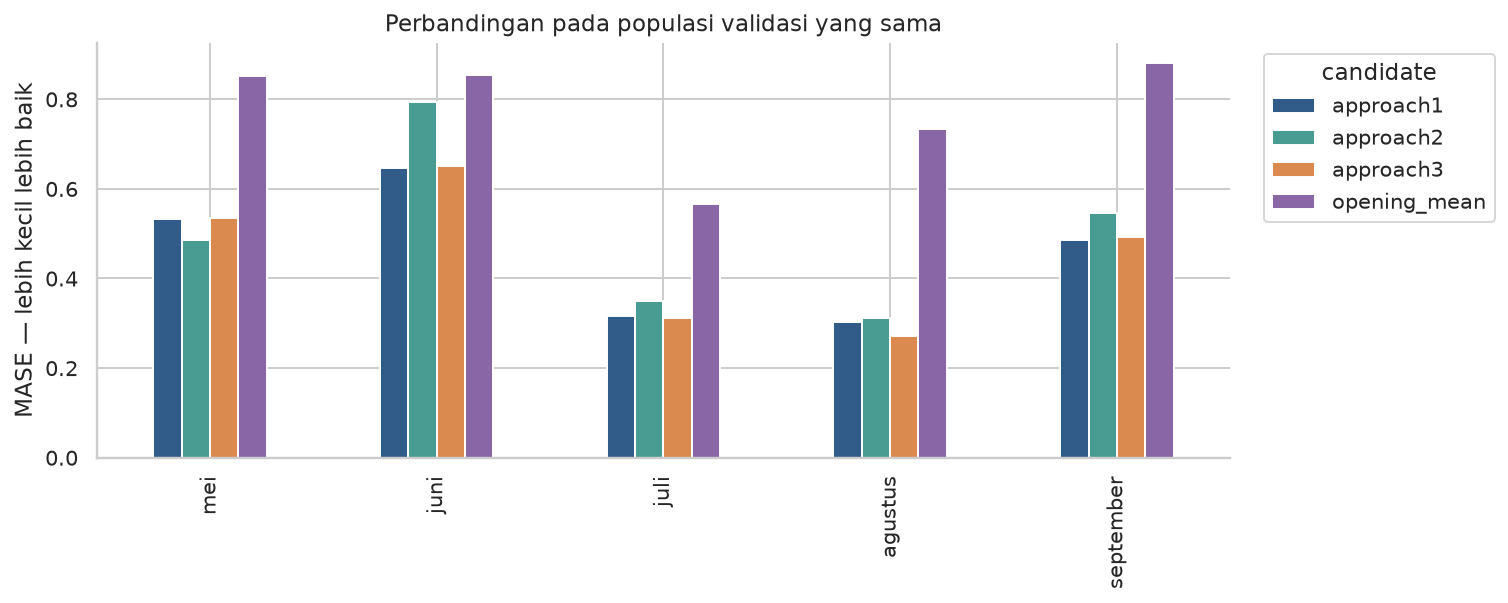





|  | candidate | MASE | film_cluster_interval95 | caveat |
| --- | --- | --- | --- | --- |
| 0 | approach1 | 0.438788 | [0.3419100092800208, 0.5736418806542259] | development periods; interval excludes model-s... |
| 1 | approach2 | 0.484760 | [0.3766833980916107, 0.620627102999723] | development periods; interval excludes model-s... |
| 2 | approach3 | 0.434681 | [0.33674715653712317, 0.5658585922801409] | development periods; interval excludes model-s... |








|  |  | mean | std | min | max |
| --- | --- | --- | --- | --- | --- |
| candidate | fold |  |  |  |  |
| approach1 | agustus | 0.303050 | 0.012501 | 0.289378 | 0.313897 |
| juli | 0.316936 | 0.002481 | 0.314079 | 0.318547 |  |
| juni | 0.648097 | 0.000781 | 0.647309 | 0.648871 |  |
| mei | 0.532239 | 0.007152 | 0.523983 | 0.536530 |  |
| september | 0.485707 | 0.004808 | 0.480418 | 0.489815 |  |
| approach2 | agustus | 0.322696 | 0.028257 | 0.303703 | 0.355169 |
| juli | 0.360160 | 0.014591 | 0.343582 | 0.371050 |  |
| juni | 0.801558 | 0.012533 | 0.789477 | 0.814499 |  |
| mei | 0.484776 | 0.001278 | 0.483332 | 0.485760 |  |
| september | 0.549960 | 0.056776 | 0.485655 | 0.593166 |  |
| approach3 | agustus | 0.275544 | 0.030984 | 0.253477 | 0.310966 |
| juli | 0.316116 | 0.008492 | 0.308689 | 0.325374 |  |
| juni | 0.652668 | 0.000756 | 0.651922 | 0.653434 |  |
| mei | 0.534742 | 0.002859 | 0.532184 | 0.537828 |  |
| september | 0.493173 | 0.005792 | 0.486716 | 0.497910 |  |

**Hasil pelatihan terdokumentasi.** Tabel/grafik berikut berasal dari eksekusi pelatihan bersih sebelumnya; pengujian inference-only memuat bobot tersimpan.





| fold | mei | juni | juli | agustus | september |
| --- | --- | --- | --- | --- | --- |
| candidate |  |  |  |  |  |
| nb_without_correction | 0.498475 | 0.830754 | 0.409021 | 0.363920 | 0.615145 |
| opening_last | 1.065638 | 0.813806 | 0.574811 | 0.726284 | 1.024072 |
| opening_mean | 0.850765 | 0.853991 | 0.567027 | 0.733156 | 0.881311 |
| static_gate | 0.534516 | 0.651311 | 0.315250 | 0.293523 | 0.497168 |
| tree_direct | 0.575886 | 0.698488 | 0.311513 | 0.303904 | 0.511350 |
| tree_hurdle | 0.531599 | 0.646885 | 0.326105 | 0.338140 | 0.513348 |
| without_actuarial_features | 0.592692 | 0.667134 | 0.288538 | 0.300482 | 0.514594 |
| without_calibration_approach1 | 0.531599 | 0.646885 | 0.326105 | 0.338140 | 0.513348 |
| without_calibration_approach2 | 0.484752 | 0.792175 | 0.351903 | 0.322751 | 0.566291 |
| without_calibration_approach3 | 0.534516 | 0.646860 | 0.316625 | 0.296837 | 0.516339 |
| without_external_approach1 | 0.531522 | 0.646475 | 0.315698 | 0.302404 | 0.485168 |
| without_external_approach2 | 0.484679 | 0.794419 | 0.349695 | 0.312346 | 0.546154 |
| without_external_approach3 | 0.534328 | 0.651276 | 0.311635 | 0.270443 | 0.492627 |








|  | candidate | axis | group | rows | MASE |
| --- | --- | --- | --- | --- | --- |
| 5 | approach1 | forecast_horizon | 1 | 1792 | 0.439024 |
| 6 | approach1 | forecast_horizon | 2 | 1792 | 0.533123 |
| 7 | approach1 | forecast_horizon | 3 | 1792 | 0.519547 |
| 8 | approach1 | forecast_horizon | 4 | 1792 | 0.415802 |
| 9 | approach1 | forecast_horizon | 5 | 1792 | 0.420299 |
| 10 | approach1 | forecast_horizon | 6 | 1792 | 0.393139 |
| 11 | approach1 | forecast_horizon | 7 | 1792 | 0.350579 |
| 33 | approach1 | scale_bin | (0.0, 5.0] | 70 | 0.702134 |
| 34 | approach1 | scale_bin | (5.0, 20.0] | 609 | 0.496364 |
| 35 | approach1 | scale_bin | (20.0, 50.0] | 1617 | 0.691194 |
| 36 | approach1 | scale_bin | (50.0, 100.0] | 2331 | 0.521892 |
| 37 | approach1 | scale_bin | (100.0, 200.0] | 2814 | 0.426464 |
| 38 | approach1 | scale_bin | (200.0, 500.0] | 2037 | 0.369788 |
| 39 | approach1 | scale_bin | (500.0, inf] | 3066 | 0.282191 |
| 40 | approach1 | target_zero | False | 8732 | 0.546978 |
| 41 | approach1 | target_zero | True | 3812 | 0.190959 |
| 47 | approach2 | forecast_horizon | 1 | 1792 | 0.588447 |
| 48 | approach2 | forecast_horizon | 2 | 1792 | 0.715716 |
| 49 | approach2 | forecast_horizon | 3 | 1792 | 0.576799 |
| 50 | approach2 | forecast_horizon | 4 | 1792 | 0.437430 |
| 51 | approach2 | forecast_horizon | 5 | 1792 | 0.413945 |
| 52 | approach2 | forecast_horizon | 6 | 1792 | 0.357856 |
| 53 | approach2 | forecast_horizon | 7 | 1792 | 0.303124 |
| 75 | approach2 | scale_bin | (0.0, 5.0] | 70 | 0.785952 |
| 76 | approach2 | scale_bin | (5.0, 20.0] | 609 | 0.563596 |
| 77 | approach2 | scale_bin | (20.0, 50.0] | 1617 | 0.735950 |
| 78 | approach2 | scale_bin | (50.0, 100.0] | 2331 | 0.588712 |
| 79 | approach2 | scale_bin | (100.0, 200.0] | 2814 | 0.488700 |
| 80 | approach2 | scale_bin | (200.0, 500.0] | 2037 | 0.397692 |
| 81 | approach2 | scale_bin | (500.0, inf] | 3066 | 0.304944 |
| 82 | approach2 | target_zero | False | 8732 | 0.615657 |
| 83 | approach2 | target_zero | True | 3812 | 0.184919 |
| 89 | approach3 | forecast_horizon | 1 | 1792 | 0.451411 |
| 90 | approach3 | forecast_horizon | 2 | 1792 | 0.547813 |
| 91 | approach3 | forecast_horizon | 3 | 1792 | 0.527450 |
| 92 | approach3 | forecast_horizon | 4 | 1792 | 0.411260 |
| 93 | approach3 | forecast_horizon | 5 | 1792 | 0.410839 |
| 94 | approach3 | forecast_horizon | 6 | 1792 | 0.372429 |
| 95 | approach3 | forecast_horizon | 7 | 1792 | 0.321565 |
| 117 | approach3 | scale_bin | (0.0, 5.0] | 70 | 0.740741 |
| 118 | approach3 | scale_bin | (5.0, 20.0] | 609 | 0.514911 |
| 119 | approach3 | scale_bin | (20.0, 50.0] | 1617 | 0.704994 |
| 120 | approach3 | scale_bin | (50.0, 100.0] | 2331 | 0.536072 |
| 121 | approach3 | scale_bin | (100.0, 200.0] | 2814 | 0.434678 |
| 122 | approach3 | scale_bin | (200.0, 500.0] | 2037 | 0.349000 |
| 123 | approach3 | scale_bin | (500.0, inf] | 3066 | 0.249038 |
| 124 | approach3 | target_zero | False | 8732 | 0.533372 |
| 125 | approach3 | target_zero | True | 3812 | 0.208614 |

Perubahan MASE akibat kontribusi eksternal (positif berarti membaik): **approach1: -0.000037**, **approach2: -0.000028**, **approach3: -0.000040**. Tanda dan besarnya perubahan harus dibaca bersama cakupan sumber yang kecil.

## 11. Interpretabilitas dan Batas Atribusi

Kontribusi prior dan neural diperiksa melalui ablation. Kontribusi gate diperiksa melalui bobot dan forecast tiap ahli. TreeSHAP di bawah menjelaskan **regressor direct Pendekatan 1**, dalam satuan target/reference; ia merupakan atribusi komponen, bukan penjelasan otomatis untuk hurdle atau seluruh campuran neural.

**Hasil pelatihan terdokumentasi.** Tabel/grafik berikut berasal dari eksekusi pelatihan bersih sebelumnya; pengujian inference-only memuat bobot tersimpan.





|  | mean absolute native TreeSHAP |
| --- | --- |
| ticket_d3 | 0.133588 |
| development_factor | 0.128161 |
| movie_ticket_d1 | 0.072605 |
| dow | 0.061451 |
| forecast_horizon | 0.043625 |
| movie_ticket_d3 | 0.034371 |
| cinema_ids | 0.030314 |
| movie_show_d3 | 0.029162 |
| movie_ratio_3_1 | 0.027458 |
| genre_primary | 0.025091 |
| movie_context_cinemas | 0.019621 |
| genre_rate | 0.018264 |
| context_holidays | 0.018153 |
| prior_ratio | 0.016732 |
| movie_show_d1 | 0.016671 |




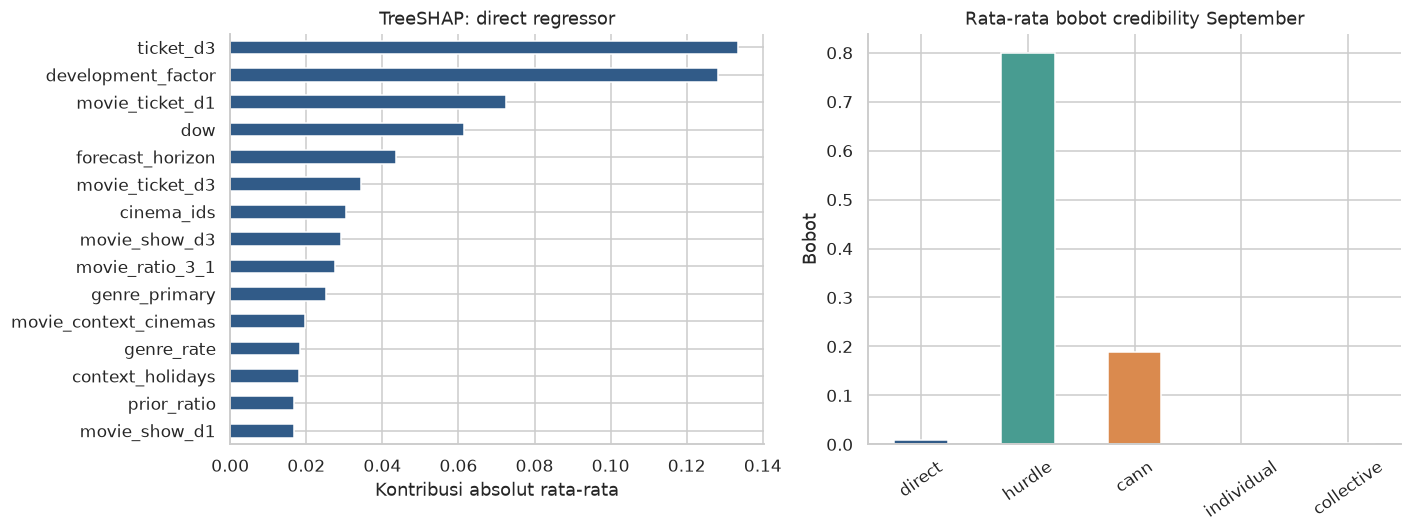

Identitas penjumlahan TreeSHAP direplay dengan galat maksimum **2.89e-15**. Besar SHAP berada pada skala regressor direct; bobot ahli adalah kontribusi algebraik model campuran, bukan bukti sebab-akibat.

**Hasil pelatihan terdokumentasi.** Tabel/grafik berikut berasal dari eksekusi pelatihan bersih sebelumnya; pengujian inference-only memuat bobot tersimpan.





|  | movie_title | city_name | forecast_horizon | scale | total_ticket | prediction_approach1 | prediction_approach2 | prediction_approach3 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 693 | MARYAM: JANJI DAN JIWA YANG TERIKAT | BATAM | 1 | 45.666667 | 0.0 | 0.0 | 16.348379 | 0.515067 |








|  | ahli | prediksi | bobot |
| --- | --- | --- | --- |
| 0 | direct | 64.734212 | 0.001858 |
| 1 | hurdle | 0.000000 | 0.967551 |
| 2 | cann | 16.305338 | 0.030026 |
| 3 | individual | 103.235813 | 0.000129 |
| 4 | collective | 31.919795 | 0.000436 |

Kasus lokal dipilih berdasarkan variasi pembukaan, bukan berdasarkan hasil paling bagus. Prediksi dan bobot merupakan rata-rata antar seed; perkalian dua rata-rata tidak identik dengan rata-rata perkalian setiap seed.

## 12. Biaya Komputasi

Catatan runtime mencakup pekerjaan nyata pada host yang tercatat di receipt. Batas model adalah 200.000.000 byte untuk setiap dependency closure; Pendekatan 3 menghitung state Pendekatan 1 dan 2 yang dipakainya. Gabungan unik state yang diserahkan juga harus berada di bawah batas tersebut. Cache pelatihan historis bukan input inferensi.

**Hasil pelatihan terdokumentasi.** Tabel/grafik berikut berasal dari eksekusi pelatihan bersih sebelumnya; pengujian inference-only memuat bobot tersimpan.





|  | fold | train_rows | valid_rows | gate_rows | seconds |
| --- | --- | --- | --- | --- | --- |
| 0 | mei | 16765 | 1750 | 0 | 37.488857 |
| 1 | juni | 35812 | 2499 | 952 | 75.809152 |
| 2 | juli | 48384 | 3983 | 2954 | 97.615071 |
| 3 | agustus | 69475 | 2142 | 8197 | 145.719436 |
| 4 | september | 91252 | 2170 | 10003 | 178.944011 |

## 13. Pelatihan Final, Penyimpanan, dan Inferensi

Setelah validasi, seluruh donor resmi yang mempunyai tujuh tanggal target lengkap digunakan untuk refit. Head Pendekatan 1 dan pilihan baseline final ditentukan dari MASE label resmi historis. Sumber eksternal tetap dibatasi pada snapshot sebelum cutoff dan forecast origin. CSV mempertahankan tepat kolom `id,total_ticket` serta urutan sample submission.

Model compact mixture pada Bagian 13.1 merupakan keluaran tambahan hasil konfigurasi beku. Tabel MASE baseline tidak diwariskan sebagai skor validasi model compact tersebut.

**Mode pengumpulan:** bobot hasil pelatihan tersebut sudah disertakan. Sel inferensi di bawah memuat seluruh pendekatan, mempertahankan urutan ID resmi, dan menghasilkan prediksi baru tanpa memanggil fungsi pelatihan.

In [26]:
def fit_final(windows,external,oof,output,iterations=300):
    output=Path(output);bundle=output/'bundle';bundle.mkdir(parents=True,exist_ok=True)
    raw=windows.loc[~windows.is_test].copy();train=expanding_features(raw,external)
    state=fit_actuarial_state(raw);query=apply_actuarial(windows.loc[windows.is_test],state,external)
    write_json(bundle/'actuarial.json',state)
    choose=min(['direct','hurdle'],key=lambda n:mase(oof,oof['pred_'+n].to_numpy()*oof.external_factor.to_numpy()))
    history,components=previous_history([oof],query.date_show.min(),set(query.base_movie_title))
    calibration=fit_calibration(history);write_json(bundle/'calibration.json',calibration)
    preds={n:[] for n in ['approach1','approach2','approach3']}
    for seed in SEEDS:
        log('final_seed',seed=seed,rows=len(train),head=choose)
        t=fit_tree(train,query,bundle/f'approach1/seed_{seed}',seed,iterations=iterations)
        n=fit_correction(train,query,bundle/f'approach2/seed_{seed}',seed,external)
        comp=dict(direct=t['direct'],hurdle=t['hurdle'],cann=n['cann'],individual=query.individual.to_numpy(),collective=query.collective.to_numpy())
        fit_gate(history,components,bundle/f'approach3/seed_{seed}',seed)
        g=gate_predict(query,comp,bundle/f'approach3/seed_{seed}')
        for name,p in [('approach1',t[choose]),('approach2',n['cann']),('approach3',g['prediction'])]:preds[name].append(p*query.external_factor.to_numpy())
    predictions={n:np.mean(p,axis=0)*calibration_multiplier(query,calibration,n) for n,p in preds.items()}
    selected=min(predictions,key=lambda n:mase(oof,oof['prediction_'+n].to_numpy()))
    write_json(bundle/'configuration.json',dict(selected=selected,approach1_head=choose,seeds=SEEDS,
        limit_bytes=LIMIT_BYTES,external_weight=.05,selection='pooled chronological official-label development MASE',
        cats=CAT_COLUMNS,device_training=DEVICE))
    # approach3 depends on both previous approaches; count its full dependency closure.
    shared=[bundle/'actuarial.json',bundle/'configuration.json',bundle/'calibration.json']
    files=lambda name:sorted((bundle/name).rglob('*'))
    sizes={}
    for name,deps in [('approach1',['approach1']),('approach2',['approach2']),('approach3',['approach1','approach2','approach3'])]:
        paths=shared+[p for d in deps for p in files(d) if p.is_file()]
        sizes[name]=sum(p.stat().st_size for p in paths)
        if sizes[name]>=LIMIT_BYTES:raise ValueError(f'{name} melebihi 200 MB')
    total=sum(p.stat().st_size for p in bundle.rglob('*') if p.is_file())
    assert total<LIMIT_BYTES
    write_json(output/'model_sizes.json',dict(each_approach_bytes=sizes,combined_unique_state_bytes=total,limit_bytes=LIMIT_BYTES,
        approach3_counts_dependencies=True))
    order=query.sort_values('id').index.to_numpy()
    for name,p in predictions.items():
        pd.DataFrame(dict(id=query.loc[order,'id'].astype(int).to_numpy(),total_ticket=p[order])).to_csv(output/(name+'.csv'),index=False)
    pd.DataFrame(dict(id=query.loc[order,'id'].astype(int).to_numpy(),total_ticket=predictions[selected][order])).to_csv(output/'submission.csv',index=False)
    write_json(output/'selection.json',dict(selected=selected,approach1_head=choose,
        scores={n:mase(oof,oof['prediction_'+n].to_numpy()) for n in predictions},reference_read=False))
    return query,predictions,selected

def replay_predictions(query,output):
    output=Path(output);bundle=output/'bundle';cfg=json.loads((bundle/'configuration.json').read_text())
    raw=query.copy();results={n:[] for n in ['approach1','approach2','approach3']}
    for seed in cfg['seeds']:
        t=tree_predict(raw,bundle/f'approach1/seed_{seed}');n=correction_predict(raw,bundle/f'approach2/seed_{seed}')
        comp=dict(direct=t['direct'],hurdle=t['hurdle'],cann=n['cann'],individual=raw.individual.to_numpy(),collective=raw.collective.to_numpy())
        g=gate_predict(raw,comp,bundle/f'approach3/seed_{seed}')
        for name,p in [('approach1',t[cfg['approach1_head']]),('approach2',n['cann']),('approach3',g['prediction'])]:results[name].append(p*raw.external_factor.to_numpy())
    calibration=json.loads((bundle/'calibration.json').read_text())
    return {n:np.mean(v,axis=0)*calibration_multiplier(raw,calibration,n) for n,v in results.items()}

In [27]:
def verify_delivery(data,windows,external,query,predictions,output):
    output=Path(output);replay=replay_predictions(query,output);errors={n:float(np.max(np.abs(replay[n]-p))) for n,p in predictions.items()}
    assert max(errors.values())<1e-6
    # Shuffling / fake future columns cannot affect the explicitly named feature schema.
    shuffled=query.sample(frac=1,random_state=42).reset_index(drop=True)
    shuffled['total_ticket']=-999999.;shuffled['occupation_rate']=999.;shuffled['total_show']=999.
    p=replay_predictions(shuffled,output)
    original_order=query.id.to_numpy();idx=pd.Index(shuffled.id).get_indexer(original_order)
    shuffle={n:float(np.max(np.abs(v[idx]-predictions[n]))) for n,v in p.items()};assert max(shuffle.values())<1e-5
    for name in ['approach1','approach2','approach3','submission']:
        f=pd.read_csv(output/(name+'.csv'),float_precision='round_trip')
        assert list(f)==['id','total_ticket'] and f.id.equals(data['sample_submission'].id)
        assert f.id.is_unique and np.isfinite(f.total_ticket).all() and f.total_ticket.ge(0).all()
    # Rebuild from shuffled source tables rather than trusting the persisted query frame.
    shuffled_data={k:(v.sample(frac=1,random_state=137).reset_index(drop=True) if isinstance(v,pd.DataFrame) else v) for k,v in data.items()}
    shuffled_data['sample_submission']=data['sample_submission']
    rebuilt=build_windows(shuffled_data);q2=apply_actuarial(rebuilt.loc[rebuilt.is_test],json.loads((output/'bundle/actuarial.json').read_text()),external)
    p2=replay_predictions(q2,output);idx2=pd.Index(q2.id).get_indexer(original_order)
    source_shuffle={n:float(np.max(np.abs(v[idx2]-predictions[n]))) for n,v in p2.items()};assert max(source_shuffle.values())<1e-4
    # Unknown categories and incomplete opening histories are stress cases, not true test inputs.
    stress=query.head(14).copy();stress['cinema_ids']='__NEW__';stress['city_name']='__NEW__';stress['genre_primary']='__NEW__'
    for d in [1,2]:
        for pre in ['ticket','show','occ','observed']:stress[f'{pre}_d{d}']=0
    stress['context_days']=1;stress['first_pair_day']=3;stress['scale']=stress.ticket_d3.div(3).clip(lower=1)
    stress=apply_actuarial(stress,json.loads((output/'bundle/actuarial.json').read_text()),external.iloc[:0].copy())
    unknown=replay_predictions(stress,output)
    assert all(np.isfinite(v).all() and (v>=0).all() for v in unknown.values())
    assert stress.external_factor.eq(1).all()
    receipt=dict(status='passed',rows=len(query),replay_max_error=errors,shuffle_and_query_label_poison_max_error=shuffle,
        shuffled_raw_inputs_max_error=source_shuffle,unknown_category_and_incomplete_history=True,
        empty_external_fallback=True,model_sizes=json.loads((output/'model_sizes.json').read_text()),
        input_policy='official ZIP and pre-cutoff external ZIP or CSV',uploaded=False,hostname=socket.gethostname())
    write_json(output/'verification.json',receipt);return receipt

**Hasil pelatihan terdokumentasi.** Tabel/grafik berikut berasal dari eksekusi pelatihan bersih sebelumnya; pengujian inference-only memuat bobot tersimpan.

```text
approach1    0.438788
approach2    0.484760
approach3    0.434681
Name: pooled development MASE, dtype: float64
```

```text
approach1    37645909
approach2      172771
approach3    37824309
Name: state bytes including dependencies, dtype: int64
```





|  | id | total_ticket |
| --- | --- | --- |
| 0 | 1 | 31.045548 |
| 1 | 2 | 26.149189 |
| 2 | 3 | 0.358381 |
| 3 | 4 | 0.142530 |
| 4 | 5 | 0.080264 |

In [28]:
PORTABLE_PIPELINE_SOURCE = (WEIGHT_ROOT/'pipeline.py').read_text()
PORTABLE_PREDICT_SOURCE = (WEIGHT_ROOT/'predict.py').read_text()

### 13.1 Pendekatan 3 lanjutan — Compact Actuarial Expert Mixture

**Hipotesis.** Skala pembukaan, horizon, pola kalender, genre, dan kota menyediakan konteks berbeda bagi respons nonlinear. Arsitektur ini menyediakan beberapa proyeksi aktuaria dan koreksi model, kemudian memilih campurannya dengan parameter routing yang telah dibekukan. Hubungan kalender diperiksa sebagai konteks yang sudah diketahui pada saat prediksi.

Untuk ahli neural, GLM NB, proyeksi pembukaan individual, dan prior kelompok membentuk $p_1,p_2,p_3$ sesuai urutan array implementasi. CANN memakai $p_1$, sedangkan ahli credibility mempelajari $\pi_\theta(x)=\operatorname{softmax}(g_\theta(x))$:

$$\hat y_{\theta}(x)=\left[\sum_{k=1}^3\pi_{\theta,k}(x)p_k(x)\right]\exp\{f_\theta(x)\}.$$

Jaringan memakai dua lapisan SiLU, lebar 64–256, AdamW, gradient clipping, dan seed 42, 137, atau 2026. Variasi objective meliputi MASE, MAE, squared log error, dan Poisson. Ahli CatBoost/LightGBM mempelajari rasio $y/\mu_{NB}$ dengan bobot $\mu_{NB}/s$ atau $\mu_{NB}$, sehingga objective dalam skala rasio tetap dapat mewakili galat pada skala tiket.

Untuk kelompok fitur $b(x)$, keluaran compact adalah

$$\hat y(x)=m_{b(x)}\left[(1-\alpha_{b(x)})\hat y_{j_b,t_b}(x)+\alpha_{b(x)}\hat y_{j_b,t'_b}(x)\right].$$

$t,t'$ adalah epoch atau jumlah pohon, $\alpha\in\{0,.25,.5,.75,1\}$, dan $m$ merupakan multiplier diskret. Prefix pohon berbagi satu model tersimpan; checkpoint neural yang dipakai disimpan satu kali. Kelompok menggunakan horizon, weekday, skala D1–D3, fase kalender, genre, dan kota. ID dan judul film tidak menjadi kunci routing. Kelompok baru memakai fallback yang tercatat dalam parameter.

**Batas interpretasi.** Router ini berasal dari optimasi adaptif pada tugas pembanding yang sama. Granularitasnya sangat tinggi dan dapat menghafal pilihan konfigurasi melalui kombinasi fitur. Kesamaan keluaran yang diukur terpisah tidak menjadi bukti generalisasi, dan hasil MASE baseline di Bagian 10 tidak boleh diklaim sebagai hasil model compact. Notebook pengumpulan memuat bobot dan menjalankan inferensi untuk konfigurasi beku; audit pemilihannya diserahkan terpisah.

In [29]:
inference_started = time.perf_counter()
compact_pred = compact_runtime.predict(
    OFFICIAL_ZIP, EXTERNAL_CSV, COMPACT_BUNDLE,
    OUTPUT / "submission.csv", OUTPUT / "compact_inference_work")
assert list(compact_pred.columns) == ["id", "total_ticket"]
assert len(compact_pred) == 72_611 and compact_pred.id.is_unique
assert compact_pred.id.equals(data["sample_submission"].id)
assert np.isfinite(compact_pred.total_ticket).all() and compact_pred.total_ticket.ge(0).all()

# Ketiga baseline memakai state tersimpan dan encoder/prior yang dibekukan.
baseline_state = json.loads((WEIGHT_ROOT / "bundle/actuarial.json").read_text())
baseline_query = baseline_runtime.apply_actuarial(windows.loc[windows.is_test], baseline_state, external)
baseline_predictions = baseline_runtime.replay_predictions(baseline_query, WEIGHT_ROOT)
for name, values in baseline_predictions.items():
    result = baseline_query[["id"]].copy()
    result["total_ticket"] = values
    result = data["sample_submission"][["id"]].merge(result, on="id", validate="one_to_one", sort=False)
    assert np.isfinite(result.total_ticket).all() and result.total_ticket.ge(0).all()
    result.to_csv(OUTPUT / (name + ".csv"), index=False)

metadata = compact_runtime.P.apply_actuarial(
    windows.loc[windows.is_test],
    json.loads((COMPACT_BUNDLE / "actuarial_state.json").read_text()), external)
receipt = {"mode": "inference-only", "rows": len(compact_pred),
    "id_order_matches_official": True, "all_values_finite_nonnegative": True,
    "training_executed": False, "weights_file_bytes": MODEL_FILE.stat().st_size,
    "uncompressed_all_approaches_bytes": package_index["uncompressed_bytes"],
    "weights_sha256": sha256(MODEL_FILE), "official_zip_sha256": sha256(OFFICIAL_ZIP),
    "external_csv_sha256": sha256(EXTERNAL_CSV), "calendar_csv_sha256": sha256(CALENDAR_CSV),
    "submission_sha256": sha256(OUTPUT / "submission.csv"),
    "seconds": time.perf_counter() - inference_started}
write_json(OUTPUT / "inference_verification.json", receipt)
display(pd.Series(receipt))
display(compact_pred.head())

mode                                                                    inference-only
rows                                                                             72611
id_order_matches_official                                                         True
all_values_finite_nonnegative                                                     True
training_executed                                                                False
weights_file_bytes                                                            96172985
uncompressed_all_approaches_bytes                                            157952063
weights_sha256                       563617f837348f97dac7879515c8c32e89a1802ac38d8e...
official_zip_sha256                  1c6270bfe72f091ce84f55f9fc29406e950423a851dad5...
external_csv_sha256                  334df979c5c2eb543bf1e25379852ddef2da263118f6f9...
calendar_csv_sha256                  bca3bb8c95ee53b94253e8859705ed9c92e13a868c69aa...
submission_sha256                    13ac86

,id,total_ticket
0,1,26.594050
1,2,22.262042
2,3,3.056157
3,4,1.011519
4,5,0.184297


### 13.2 Diagnostik router, kalender, dan biaya inferensi

Pemeriksaan berikut menghitung ukuran kelompok, konsentrasi pemilihan ahli, dan peran kalender dari keluaran aktual. Kelompok beranggota tunggal menunjukkan risiko penghafalan konfigurasi. Grafik ini merupakan deskripsi parameter dan input, bukan atribusi kausal. Tabel ukuran menghitung seluruh dependensi inferensi tiap pendekatan serta gabungannya tanpa kompresi.

observed_groups              63963.000000
singleton_groups             57101.000000
rows_in_singleton_groups     57101.000000
rows_per_group_median            1.000000
largest_group                    6.000000
mean_interpolation_weight        0.662458
mean_multiplier                  1.619620
dtype: float64

,id,published,url
0,setneg_2025_cuti,2025-01-24,https://setneg.go.id/baca/index/presiden_tetap...
1,setneg_2026_skb,2025-09-19,https://www.setneg.go.id/baca/index/inilah_skb...
2,official_calendar_and_skb_2025,2024-10-14,https://cdn.undiksha.ac.id/wp-content/uploads/...


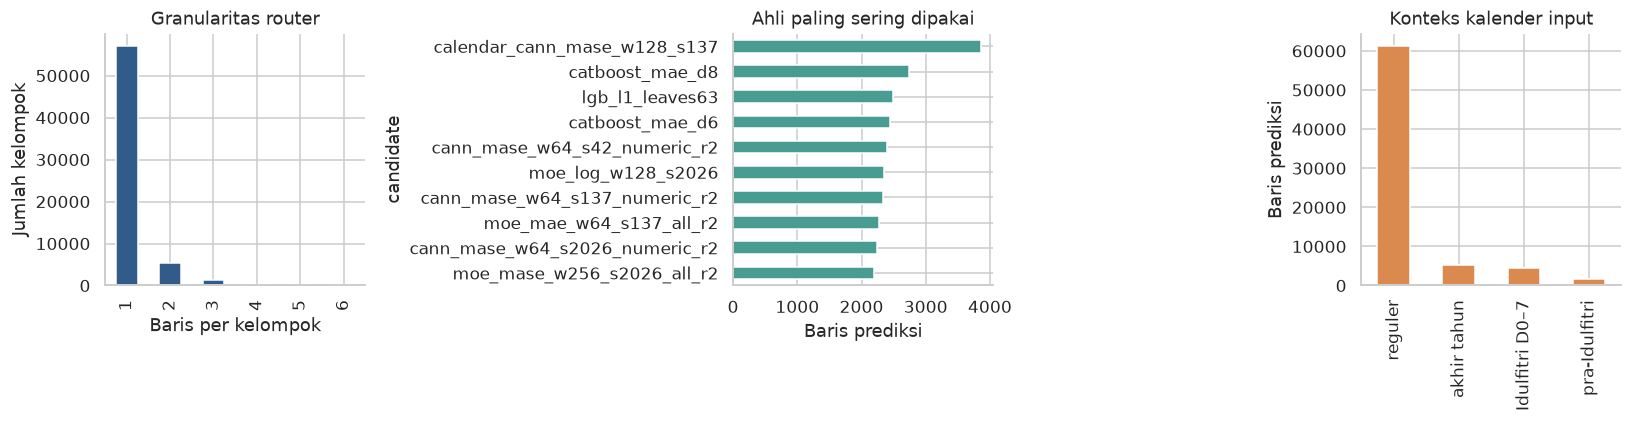

In [30]:
# Impor runtime dari kode yang baru ditulis; tidak bergantung pada workspace privat.
sys.path.insert(0,str(COMPACT_SOURCE))
import forecast_runtime as compact_runtime
import calendar_features as compact_calendar

group_values=compact_runtime.group_ids(metadata,COMPACT_RECIPE,COMPACT_BUNDLE/'calendar.json')
group_counts=pd.Series(group_values).value_counts()
routes=[COMPACT_RECIPE['groups'].get(str(int(g)),COMPACT_RECIPE['fallback']) for g in group_values]
route_frame=pd.DataFrame(routes)
extra,phase=compact_calendar.calendar_features(metadata,COMPACT_BUNDLE/'calendar.json')
display(pd.Series({'observed_groups':len(group_counts),'singleton_groups':int(group_counts.eq(1).sum()),
    'rows_in_singleton_groups':int(group_counts.loc[group_counts.eq(1)].sum()),
    'rows_per_group_median':group_counts.median(),'largest_group':group_counts.max(),
    'mean_interpolation_weight':route_frame.alpha.mean(),'mean_multiplier':route_frame.multiplier.mean()}))
display(pd.DataFrame(COMPACT_CALENDAR['sources']))
fig,axes=plt.subplots(1,3,figsize=(15,4))
group_counts.value_counts().sort_index().plot.bar(ax=axes[0],color=COLORS[0]);axes[0].set(title='Granularitas router',xlabel='Baris per kelompok',ylabel='Jumlah kelompok')
route_frame.candidate.value_counts().head(10).iloc[::-1].plot.barh(ax=axes[1],color=COLORS[1]);axes[1].set(title='Ahli paling sering dipakai',xlabel='Baris prediksi')
pd.Series(phase).map({0:'reguler',1:'pra-Idulfitri',2:'Idulfitri D0–7',3:'pasca D8–14',4:'akhir tahun'}).value_counts().plot.bar(ax=axes[2],color=COLORS[2]);axes[2].set(title='Konteks kalender input',ylabel='Baris prediksi')
finish_figure('compact_router_diagnostics')

## 14. Pembahasan dan Jawaban Pertanyaan Penelitian

Sel berikut merangkum hasil aktual. Pengaruh fitur aktuaria, koreksi neural, gate, dan eksternal harus didukung oleh ablation pada populasi yang sama. Dataset eksternal yang kecil dapat tidak membantu meskipun masuk akal secara konseptual.

RQ1: ablation tanpa fitur aktuaria mencapai MASE 0.447539; Pendekatan 1 mencapai 0.438788. Ini juga dipengaruhi pilihan head historis dan tidak membuktikan kausalitas setiap fitur.

RQ2: prior NB tanpa koreksi mencapai 0.533474; koreksi neural mencapai 0.484760.

RQ3: gate statis mencapai 0.440549; learned credibility mencapai 0.434681.

RQ4: variasi bulanan, seed, dan kelompok film dilaporkan pada tabel validasi serta bootstrap; pengaruh eksternal tercatat pada ablation tanpa eksternal.

RQ5: semua dependency closure lulus batas ukuran; baseline beserta kode berukuran 37.88 MB; seluruh baseline dan compact mixture beserta kode berukuran 157.86 MB, dengan replay dan stress tests berstatus passed.

## 15. Keterbatasan

- Lima bulan merupakan data pengembangan yang dapat sudah dieksplorasi sebelumnya. Pemisahan kronologis dan film mengurangi kebocoran, tetapi tidak menghasilkan estimasi hidden-test yang bebas selection bias.
- Nol pada grid mengikuti kontrak kompetisi pada tanggal dengan pencatatan global; data tidak membedakan penutupan tayang, transaksi nol, dan beberapa kegagalan pencatatan di tingkat penyebab. Window yang melintasi tanggal global tanpa transaksi dikeluarkan. Penyaringan observabilitas ini mengubah populasi validasi; skornya tidak dibandingkan langsung sebagai peningkatan terhadap populasi yang masih memuat celah tersebut.
- Pembukaan historis di awal April dapat tersensor kiri. Flag disediakan, sementara slice pembukaan baru dapat memiliki prevalensi sensor kiri berbeda.
- Prior kelompok dan dispersion NB adalah adaptasi empiris untuk tiket. Jaringan yang memakai loss MASE tidak otomatis menyediakan distribusi probabilistik terkalibrasi.
- Cakupan eksternal kecil dan tidak cocok langsung dengan judul test. Admissions nasional, kumulatif, dan showtimes memiliki grain serta satuan berbeda.
- TreeSHAP menjelaskan komponen direct; ia tidak menjadi atribusi lengkap untuk kuantil, peluang nol, ataupun neural gate.
- Kategori baru menggunakan fallback; stress test finiteness tidak membuktikan akurasi pada kategori tersebut.
- Tidak ada skor hidden-test atau hasil pengumpulan kompetisi yang diasumsikan dari validasi lokal.
- Router compact menggunakan kelompok fitur yang sangat granular. Parameter router dipilih melalui evaluasi adaptif pada tugas pembanding yang sama, sehingga hasil kesesuaian di sana bukan validasi independen. Banyak kelompok hanya berisi satu baris; ukuran model yang kecil tidak membuktikan kemampuan generalisasi. Rincian pemilihan dan pengukuran kesesuaian disimpan dalam audit terpisah.
- Aturan router merupakan parameter hasil optimasi. Hubungan kalender, skala, genre, dan kota memotivasi kandidat fitur, tetapi bukan pembuktian kausal atau pembenaran post hoc untuk setiap pilihan ahli.

## 16. Kesimpulan

Validasi kronologis pelatihan baseline memilih **approach3** dengan MASE pooled pengembangan **0.434681**. Notebook pengumpulan memuat state ketiga baseline dan compact mixture, kemudian menghasilkan **72.611 baris** prediksi baru tanpa pelatihan ulang. Ukuran seluruh state tersimpan tetap di bawah 200.000.000 byte. Kesesuaian pada tugas pembanding dibatasi oleh pemilihan router adaptif; hal tersebut tidak menjadi estimasi akurasi hidden-test.

## 17. Referensi

[1] Richman, R. “Mind the gap — safely incorporating deep learning models into the actuarial toolkit.” *British Actuarial Journal*. [Artikel](https://www.cambridge.org/core/journals/british-actuarial-journal/article/mind-the-gap-safely-incorporating-deep-learning-models-into-the-actuarial-toolkit/4716B70DF7B06258DBB42F068790B156).

[2] Richman, R., Scognamiglio, S., dan Wüthrich, M. V. “The Credibility Transformer.” arXiv:2409.16653, 2024. [Makalah](https://arxiv.org/abs/2409.16653).

[3] Hyndman, R. J. dan Athanasopoulos, G. *Forecasting: Principles and Practice*, edisi ketiga. [Buku](https://otexts.com/fpp3/).

[4] Ke, G., et al. “LightGBM: A Highly Efficient Gradient Boosting Decision Tree.” NeurIPS, 2017. [Makalah](https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html).

[5] Dokumentasi kompetisi JOINTS 2026: skema input, horizon D4–D10, dan MASE dengan mean pembukaan sebagai skala.

[6] Notebook referensi: Three Makasih (final, Soal 1, Soal 2), untuk pola EDA dan perbandingan pendekatan; Tembok Ratapan Solo SSF 2026 Technical Report, untuk struktur laporan. Implementasi, angka, dan eksperimen domain tiket diturunkan kembali.

[7] Arsip eksternal Cinepoint historis sebelum 30 September 2025. URL penerbit, available_at, source_updated_at, dan hash snapshot terdapat pada source manifest arsip input.

[8] Sekretariat Negara. [SKB libur nasional dan cuti bersama 2026](https://www.setneg.go.id/baca/index/inilah_skb_3_menteri_libur_nasional_dan_cuti_bersama_2026), 19 September 2025.

[9] Sekretariat Negara. [Cuti bersama ASN 2025](https://setneg.go.id/baca/index/presiden_tetapkan_keputusan_baru_mengenai_hari_cuti_bersama_asn_tahun_2025), 24 Januari 2025.

[10] SKB 3 Menteri, 14 Oktober 2024. [Kalender libur dan cuti bersama 2025, salinan institusional](https://cdn.undiksha.ac.id/wp-content/uploads/sites/7/2025/01/22135503/Libur-Nasional-dan-Cuti-Bersama-2025.pdf).